# Entrega final — Proyecto de aula · Minería de Datos
## Modelo de clasificación para la predicción temprana de diabetes tipo 2 a partir de indicadores clínicos

**Autor:** Juan Ortega
**Curso:** Minería de Datos — Universidad de la Costa (CUC) · **Departamento:** Ciencias de la Computación y Electrónica
**Tipo de proyecto:** Clasificación (binaria) — investigación aplicada
**Pregunta de investigación:** ¿Es posible clasificar, a partir de indicadores clínicos básicos, si una paciente del conjunto Pima presenta diabetes, y qué tipo de error resulta más relevante para este problema?
**Dataset:** Pima Indians Diabetes Database (NIDDK; Smith et al., 1988). Descarga: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database. 768 registros, 8 predictoras numéricas.
**Variable objetivo:** `Outcome` (1 = diabética, 0 = no diabética).
**Período:** Corte 3 (entrega final) — incluye el EDA y los modelos base de los cortes 1 y 2, la revisión del rendimiento, el modelo final y el pipeline usado por la aplicación Streamlit.

## 1. Descripción del conjunto de datos

El conjunto de datos utilizado es **Pima Indians Diabetes Dataset**, originalmente publicado por el
National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK). Contiene registros médicos
de **768 pacientes mujeres** de al menos 21 años, de ascendencia Pima (Arizona, EE.UU.), con el
objetivo de predecir si una paciente desarrollará diabetes tipo 2 (variable `Outcome`) a partir de
mediciones clínicas y demográficas.

Este dataset fue seleccionado porque:
- Contiene exactamente las variables clínicas mencionadas en el objetivo del proyecto (glucosa,
  presión arterial, IMC, antecedentes de embarazos).
- Es un problema de **clasificación binaria** (0 = no diabética, 1 = diabética), adecuado para
  comparar distintos algoritmos de clasificación en los siguientes períodos.
- Es un dataset ampliamente documentado en la literatura, lo que facilita comparar resultados
  propios contra trabajos previos.


In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

df = pd.read_csv("diabetes.csv")
df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Descripción de las variables

| Variable | Tipo | Descripción |
|---|---|---|
| `Pregnancies` | Numérica (entera) | Número de embarazos previos |
| `Glucose` | Numérica (entera) | Concentración de glucosa en plasma (prueba de tolerancia oral, 2h) |
| `BloodPressure` | Numérica (entera) | Presión arterial diastólica (mm Hg) |
| `SkinThickness` | Numérica (entera) | Grosor del pliegue cutáneo del tríceps (mm) |
| `Insulin` | Numérica (entera) | Insulina sérica a las 2 horas (mu U/ml) |
| `BMI` | Numérica (decimal) | Índice de masa corporal (peso en kg / (altura en m)^2) |
| `DiabetesPedigreeFunction` | Numérica (decimal) | Función que estima la probabilidad de diabetes según antecedentes familiares |
| `Age` | Numérica (entera) | Edad de la paciente (años) |
| `Outcome` | Categórica (binaria) | Variable objetivo: 1 = diabética, 0 = no diabética |

Todas las variables predictoras son numéricas, lo cual simplifica la fase de preparación de datos
(no se requiere codificación de variables categóricas en este dataset).


In [2]:
# Dimensiones y tipos de datos
print("Dimensiones del dataset:", df.shape)
print()
print("Tipos de datos:")
print(df.dtypes)


Dimensiones del dataset: (768, 9)

Tipos de datos:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


In [3]:
# Estadísticas descriptivas generales
df.describe()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## 3. Diagnóstico inicial de calidad de datos

Un primer chequeo con `isnull()` no muestra valores faltantes explícitos. Sin embargo, este dataset
es un caso conocido en el que los valores faltantes fueron codificados como **cero (0)** en variables
donde un valor de cero es clínicamente imposible (por ejemplo, glucosa o presión arterial igual a 0).
Por eso se revisan por separado los ceros en las columnas donde no tienen sentido fisiológico.


In [4]:
# Valores nulos explícitos
print("Valores nulos por columna:")
print(df.isnull().sum())
print()

# Duplicados
print("Filas duplicadas:", df.duplicated().sum())


Valores nulos por columna:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Filas duplicadas: 0


In [5]:
# Ceros clínicamente imposibles (posibles valores faltantes disfrazados)
cols_sin_ceros_validos = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

resumen_ceros = pd.DataFrame({
    "columna": cols_sin_ceros_validos,
    "num_ceros": [(df[c] == 0).sum() for c in cols_sin_ceros_validos],
    "porcentaje": [round((df[c] == 0).mean() * 100, 1) for c in cols_sin_ceros_validos]
})
resumen_ceros


,columna,num_ceros,porcentaje
0,Glucose,5,0.7
1,BloodPressure,35,4.6
2,SkinThickness,227,29.6
3,Insulin,374,48.7
4,BMI,11,1.4


**Hallazgos del diagnóstico inicial:**

- No hay valores nulos explícitos (`NaN`) ni filas duplicadas en el dataset.
- Sin embargo, se identificaron **valores de cero clínicamente imposibles** que funcionan como
  valores faltantes ocultos:
  - `Insulin`: 374 registros en cero (~48.7% del dataset) — el problema más severo.
  - `SkinThickness`: 227 registros en cero (~29.6%).
  - `BloodPressure`: 35 registros en cero (~4.6%).
  - `BMI`: 11 registros en cero (~1.4%).
  - `Glucose`: 5 registros en cero (~0.7%).
- La variable objetivo `Outcome` está moderadamente desbalanceada: 500 pacientes sin diabetes (65.1%)
  frente a 268 con diabetes (34.9%). Esto deberá tenerse en cuenta al entrenar y evaluar los modelos
  en los siguientes períodos (por ejemplo, evitar depender solo de la exactitud como métrica).


## 4. Proceso de limpieza (fase inicial) — versión usada solo para EDA

En este primer período se realiza una limpieza preliminar: se reemplazan los ceros clínicamente
imposibles por `NaN` para tratarlos explícitamente como valores faltantes, y se imputan usando la
**mediana** de cada variable (más robusta que la media frente a valores atípicos). La estrategia de
imputación definitiva (mediana simple, imputación por grupo según `Outcome`, KNN imputer, etc.) se
terminará de evaluar y justificar en el siguiente período, junto con la fase de modelado.


> **Nota (corte 2):** esta imputación con la mediana de *todo* el dataset se conserva únicamente para el análisis exploratorio. Para el modelado se usa una imputación dentro de un `Pipeline` ajustada solo con los datos de entrenamiento (ver sección 10), para evitar fuga de información.

In [6]:
df_limpio = df.copy()

# Paso 1: reemplazar ceros clínicamente imposibles por NaN
for c in cols_sin_ceros_validos:
    df_limpio[c] = df_limpio[c].replace(0, np.nan)

print("Valores faltantes tras marcar los ceros como NaN:")
print(df_limpio.isnull().sum())


Valores faltantes tras marcar los ceros como NaN:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [7]:
# Paso 2: imputación preliminar con la mediana de cada columna
for c in cols_sin_ceros_validos:
    mediana = df_limpio[c].median()
    df_limpio[c] = df_limpio[c].fillna(mediana)

print("Valores faltantes después de la imputación:")
print(df_limpio.isnull().sum())
print()
df_limpio.describe()


Valores faltantes después de la imputación:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.656250,72.386719,29.108073,140.671875,32.455208,0.471876,33.240885,0.348958
std,3.369578,30.438286,12.096642,8.791221,86.383060,6.875177,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## 5. Visualizaciones exploratorias

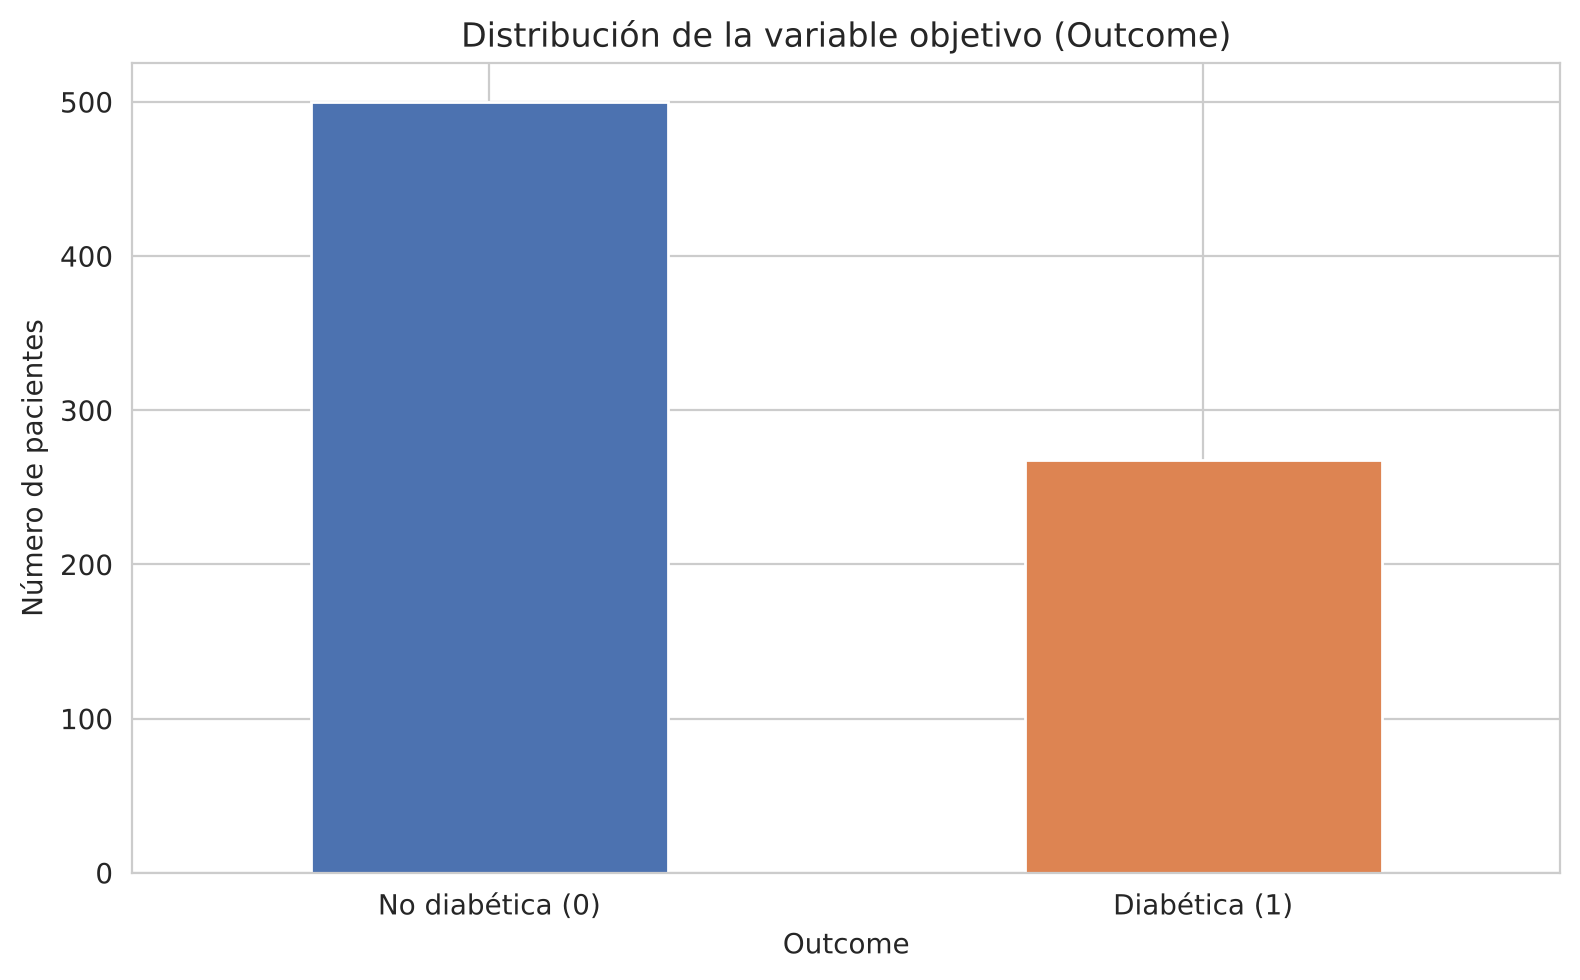

In [8]:
# Distribución de la variable objetivo
fig, ax = plt.subplots()
df["Outcome"].value_counts().sort_index().plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_xticklabels(["No diabética (0)", "Diabética (1)"], rotation=0)
ax.set_ylabel("Número de pacientes")
ax.set_title("Distribución de la variable objetivo (Outcome)")
plt.tight_layout()
plt.show()


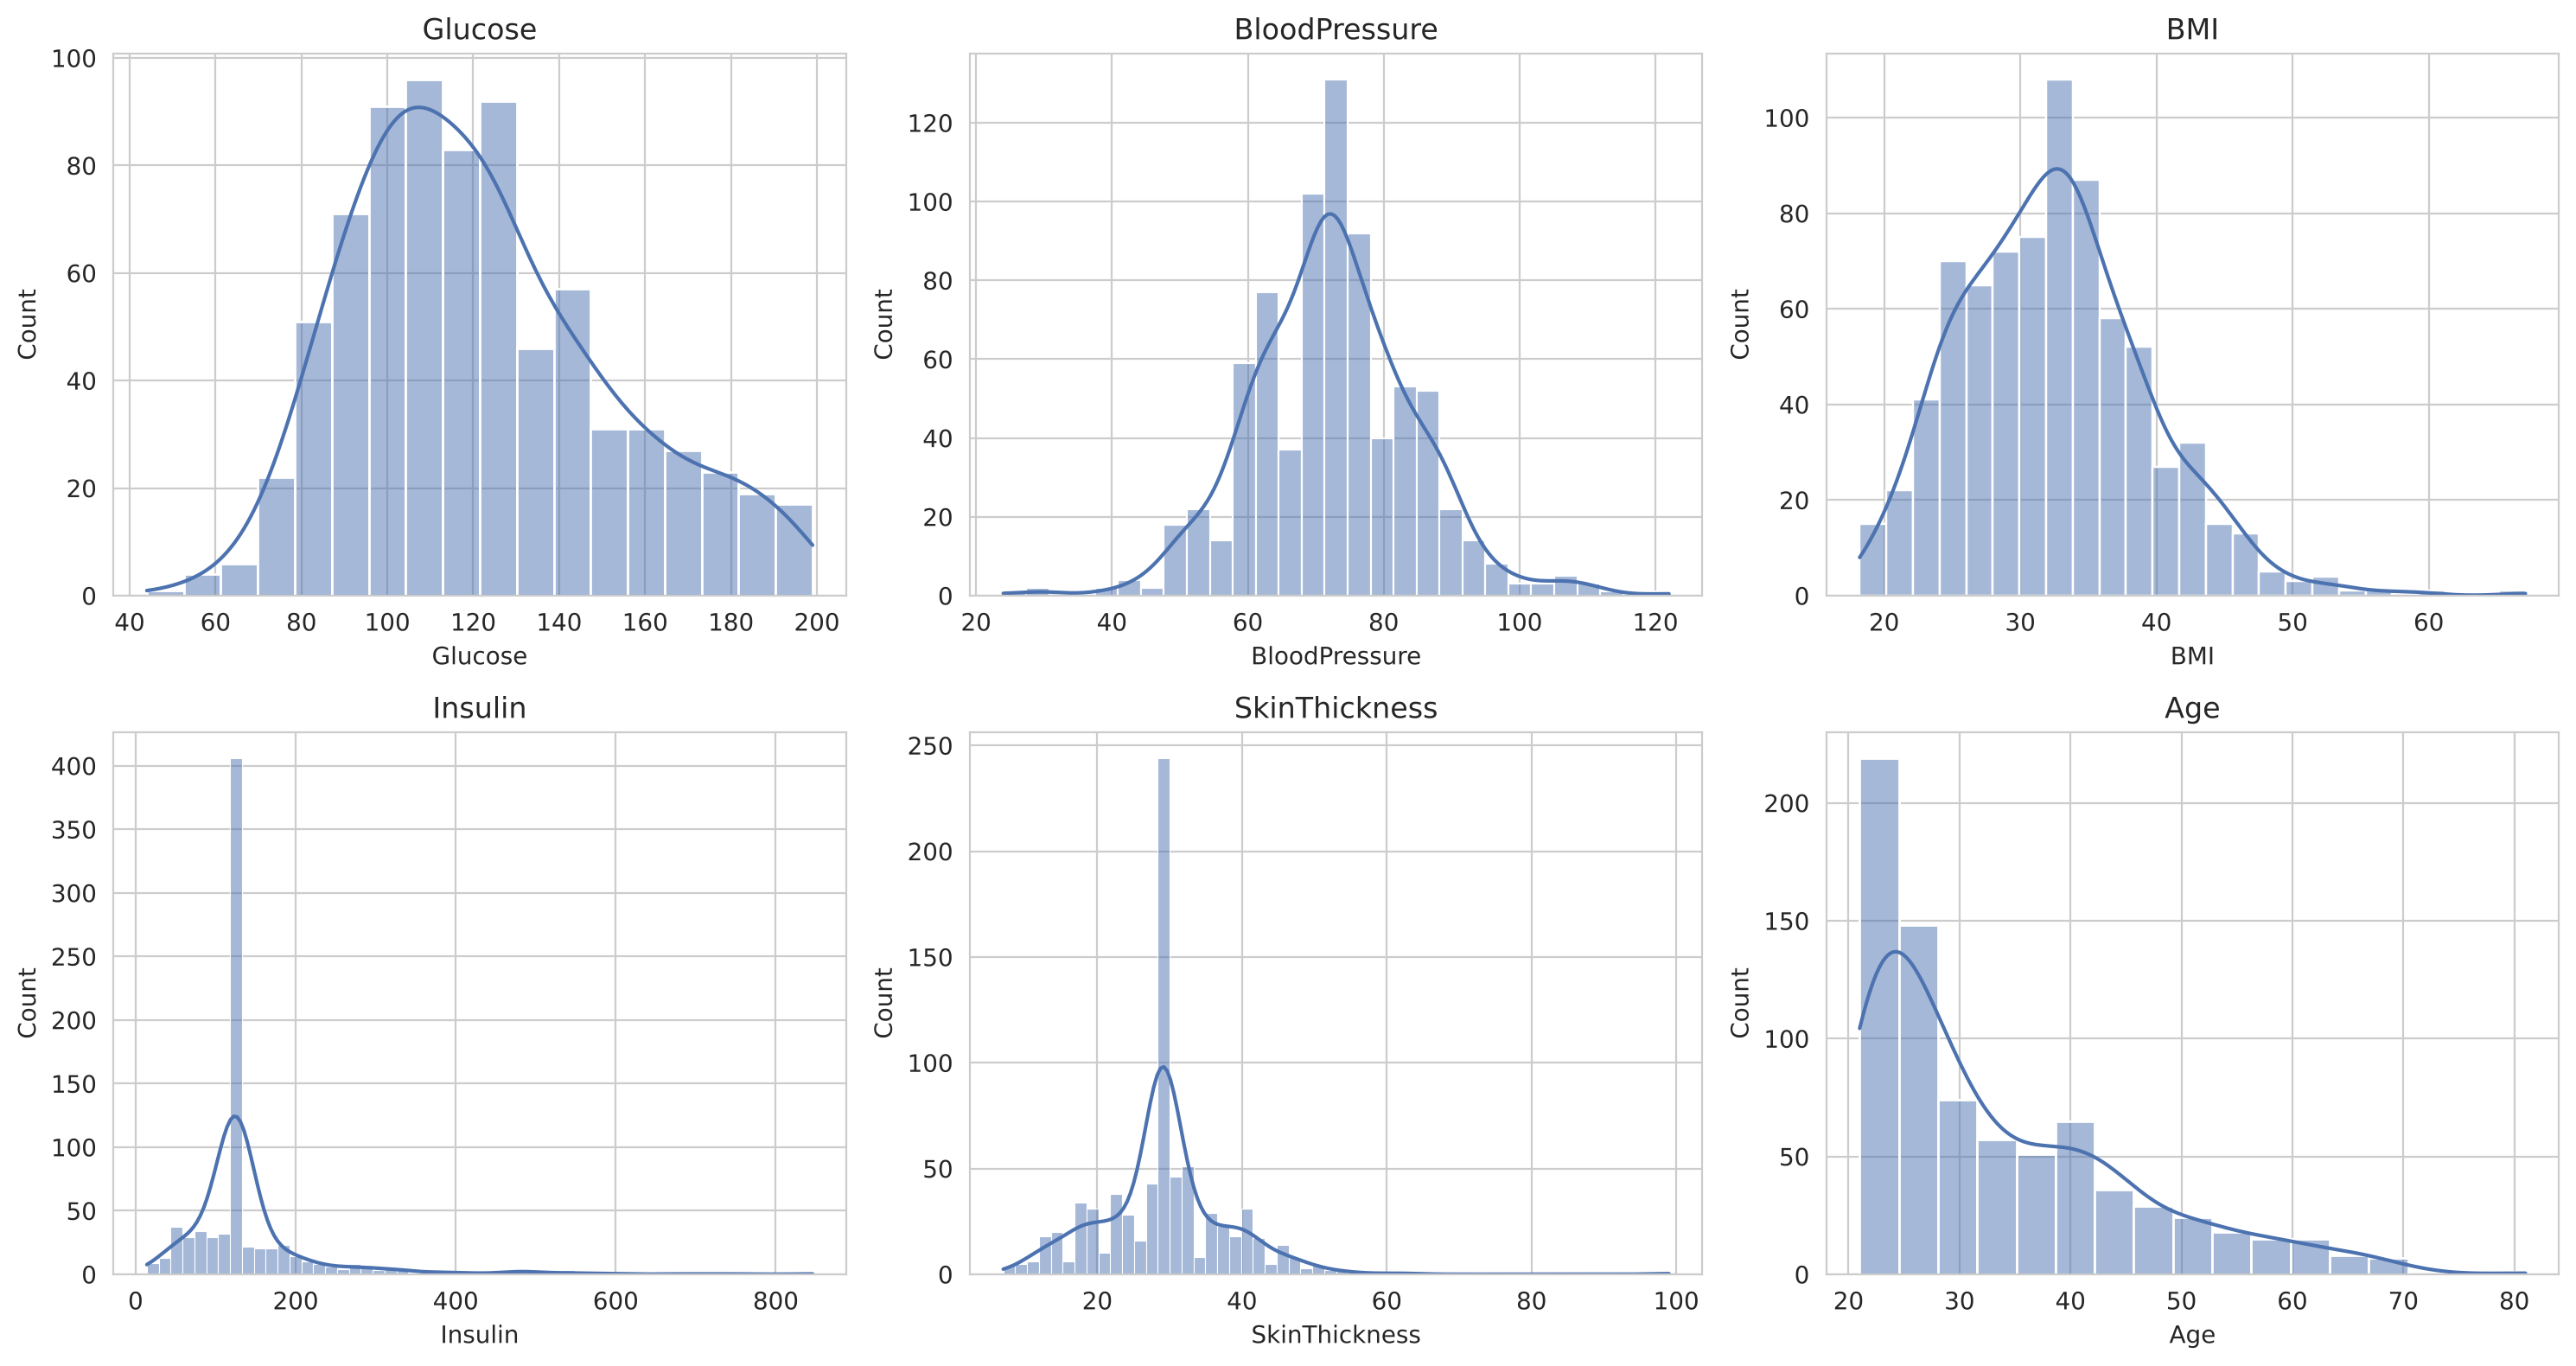

In [9]:
# Distribución de las variables numéricas principales (después de la limpieza)
variables = ["Glucose", "BloodPressure", "BMI", "Insulin", "SkinThickness", "Age"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), variables):
    sns.histplot(df_limpio[col], kde=True, ax=ax, color="#4C72B0")
    ax.set_title(col)
plt.tight_layout()
plt.show()


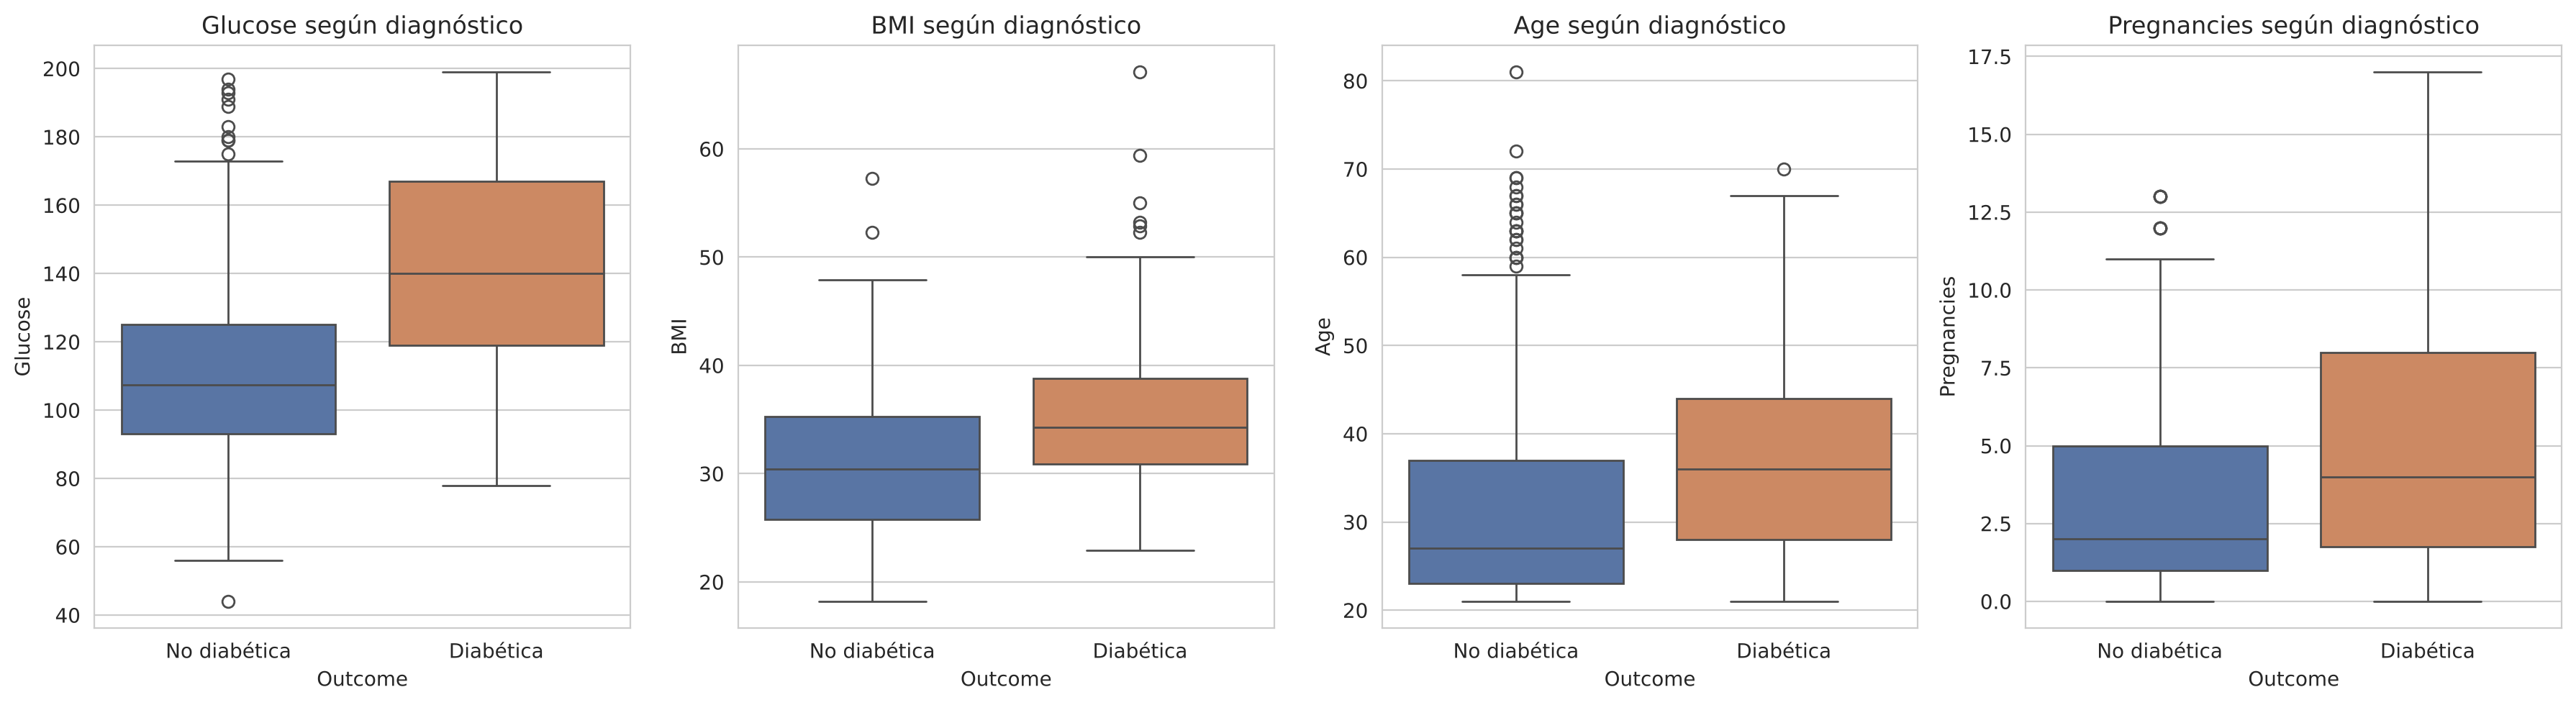

In [10]:
# Comparación de variables clave según diagnóstico (Outcome)
variables_clave = ["Glucose", "BMI", "Age", "Pregnancies"]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, col in zip(axes, variables_clave):
    sns.boxplot(data=df_limpio, x="Outcome", y=col, hue="Outcome", legend=False,
                ax=ax, palette=["#4C72B0", "#DD8452"])
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No diabética", "Diabética"])
    ax.set_title(f"{col} según diagnóstico")
plt.tight_layout()
plt.show()

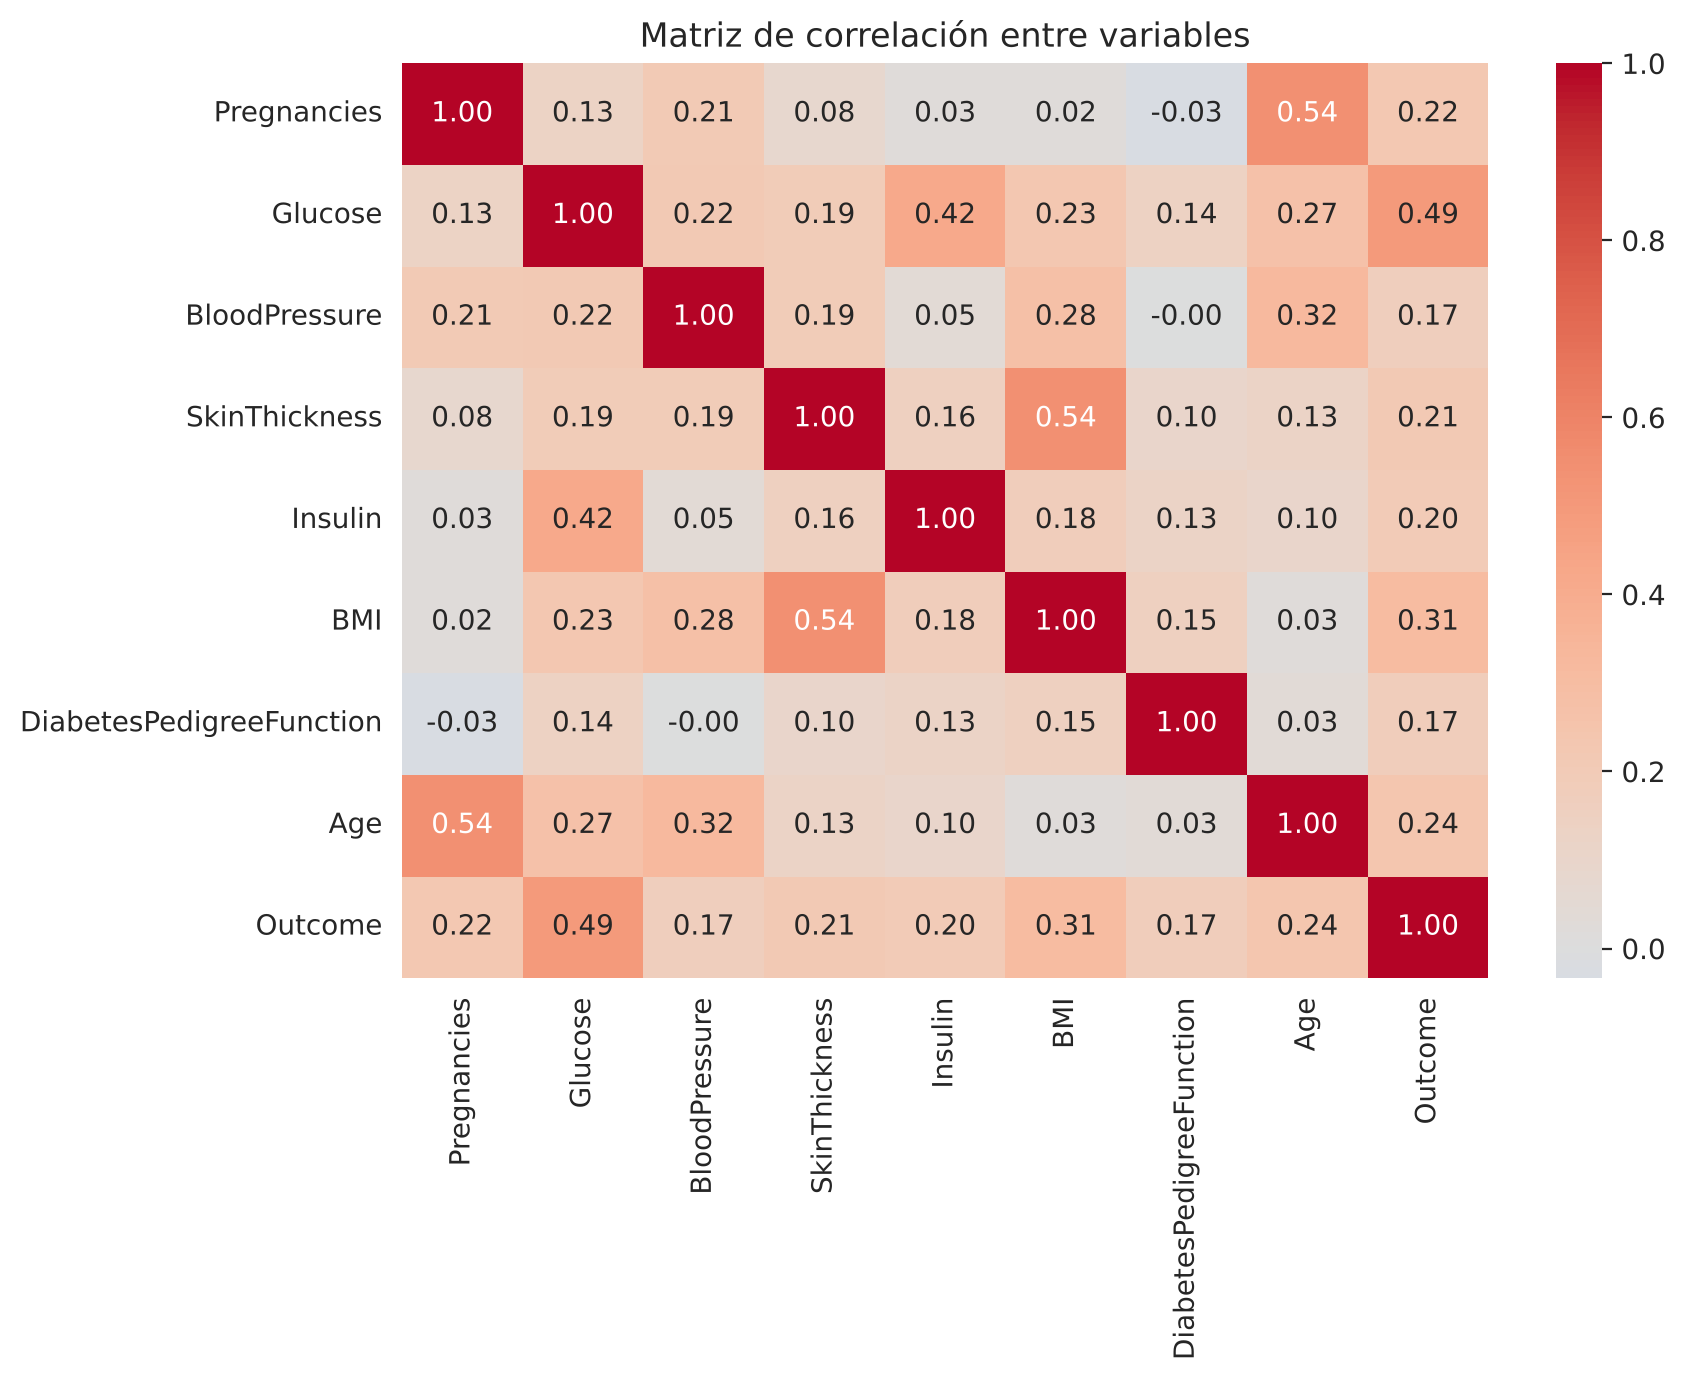

In [11]:
# Matriz de correlación entre variables
plt.figure(figsize=(9, 7))
corr = df_limpio.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación entre variables")
plt.tight_layout()
plt.show()


**Lectura de las visualizaciones:**

- Las pacientes diagnosticadas con diabetes (`Outcome = 1`) muestran de forma visible niveles de
  **glucosa** más altos que las no diagnosticadas, lo cual es consistente con el criterio clínico
  usado para definir la enfermedad.
- El **IMC** y la **edad** también muestran diferencias entre ambos grupos, aunque con más
  solapamiento que la glucosa.
- La matriz de correlación muestra que `Glucose` es la variable con mayor correlación positiva con
  `Outcome`, seguida de `BMI`, `Age` y `Pregnancies`. Ninguna variable predictora muestra
  correlaciones extremadamente altas entre sí, por lo que no se anticipan problemas graves de
  multicolinealidad para el modelado.


## 6. Registro de uso de IA (primer avance)

- **Propósito del uso de la IA:** apoyo en la redacción de la introducción y el estado del arte del
  documento PDF, búsqueda y verificación de referencias académicas del Departamento de Ciencias de
  la Computación y Electrónica de la CUC, y estructuración inicial de este cuaderno (diagnóstico de
  calidad de datos, limpieza preliminar y visualizaciones exploratorias).
- **¿Qué respuesta fue útil?** La identificación automática de los ceros clínicamente imposibles
  como valores faltantes ocultos, y la sugerencia de usar la mediana (en lugar de la media) para la
  imputación preliminar dado el número de valores faltantes en `Insulin` y `SkinThickness`.
- **Lo que había que corregir, validar o ajustar:** se verificó manualmente que las cinco
  referencias del estado del arte correspondieran a publicaciones reales de autores del
  departamento (no inventadas por el modelo), confirmando autores, año y DOI contra fuentes
  primarias antes de incluirlas en el documento final.
- **Decisiones tomadas por el grupo y no por la herramienta de IA:** la elección del dataset
  (Pima Indians Diabetes) y la definición del problema como clasificación binaria fueron decisiones
  del equipo, tomadas antes de usar la IA. La estrategia definitiva de imputación de valores
  faltantes y la selección de algoritmos de clasificación para el siguiente período quedan
  pendientes de decisión del grupo, con apoyo de la IA como una segunda opinión, no como
  reemplazo del criterio propio.


## 7. Conclusión del primer avance (registro histórico)

*Se conserva como registro del primer avance; las decisiones definitivas están en las secciones 12.4 a 13.*

En esta primera revisión del conjunto de datos se confirmó que el dataset Pima Indians Diabetes es
adecuado para el objetivo del proyecto: contiene las variables clínicas necesarias (glucosa, presión
arterial, IMC, embarazos) y una variable objetivo binaria clara. El principal problema de calidad de
datos identificado fue la presencia de **ceros clínicamente imposibles** en cinco variables, que
actúan como valores faltantes ocultos, siendo especialmente severo en `Insulin` (48.7%) y
`SkinThickness` (29.6%). Como ajuste inicial, se marcaron estos ceros como valores nulos y se
imputaron de forma preliminar con la mediana de cada variable, únicamente con fines exploratorios.

Durante el segundo período académico se espera: (1) definir y justificar la estrategia de
imputación definitiva (comparando mediana simple, imputación por grupo según `Outcome` e
imputación por KNN), (2) tratar el desbalance moderado de la variable `Outcome`, y (3) entrenar y
comparar distintos algoritmos de clasificación (por ejemplo, regresión logística, árboles de
decisión y random forest) sobre el conjunto de datos limpio, evaluando su desempeño con métricas
adecuadas para un problema desbalanceado (precisión, recall, F1-score y AUC-ROC), en línea con el
enfoque metodológico revisado en el estado del arte.


---
# CORTE 2
## 8. Cambios frente al primer avance

| Cambio | Justificación |
|---|---|
| La imputación con mediana pasa a hacerse **dentro de un `Pipeline`, ajustada solo con entrenamiento**. | Calcular la mediana con todo el dataset filtra información del conjunto de prueba (*data leakage*). La versión global (`df_limpio`) queda solo para EDA. |
| Se imprimen los conteos de `Outcome` y las correlaciones con la variable objetivo. | En el primer avance estas cifras se afirmaban en texto sin mostrarlas. |
| Se corrigieron las advertencias de `seaborn`/`matplotlib` del boxplot. | Código más limpio y reproducible. |
| No se cambió el dataset, la pregunta ni la variable objetivo. | Continuidad con el primer avance. |


## 9. Análisis exploratorio de datos (EDA) orientado a la pregunta

### 9.1 Variable objetivo y desbalance

In [12]:
conteo = df["Outcome"].value_counts().sort_index()
prop = (df["Outcome"].value_counts(normalize=True).sort_index() * 100).round(1)
print(pd.DataFrame({"pacientes": conteo, "porcentaje": prop}).rename(index={0: "No diabética (0)", 1: "Diabética (1)"}))

                  pacientes  porcentaje
Outcome                                
No diabética (0)        500        65.1
Diabética (1)           268        34.9


**Interpretación:** hay un desbalance moderado (~65 % / 35 %). Un modelo que predijera siempre «no diabética» tendría ~65 % de accuracy sin detectar a ninguna paciente enferma, por eso el accuracy no será el único criterio de comparación.

### 9.2 ¿Los valores faltantes (ceros) se distribuyen igual en ambas clases?

In [13]:
falt = pd.DataFrame({
    c: (df[df["Outcome"] == k][c] == 0).mean() * 100
    for c in cols_sin_ceros_validos for k in [0]
}, index=["% ceros en No diabética"]).T
falt["% ceros en Diabética"] = [(df[df["Outcome"] == 1][c] == 0).mean() * 100 for c in cols_sin_ceros_validos]
print(falt.round(1))

               % ceros en No diabética  % ceros en Diabética
Glucose                            0.6                   0.7
BloodPressure                      3.8                   6.0
SkinThickness                     27.8                  32.8
Insulin                           47.2                  51.5
BMI                                1.8                   0.7


**Interpretación:** si el porcentaje de ceros difiere entre clases, la ausencia del dato podría estar asociada al diagnóstico (no es completamente aleatoria). Esto justifica evaluar en el futuro un indicador de «dato faltante» o imputación más sofisticada; en este corte se usa la mediana como línea base.

### 9.3 Valores atípicos

Pregnancies                   4
Glucose                       0
BloodPressure                14
SkinThickness                87
Insulin                     346
BMI                           8
DiabetesPedigreeFunction     29
Age                           9
Name: n_atípicos (regla IQR), dtype: int64


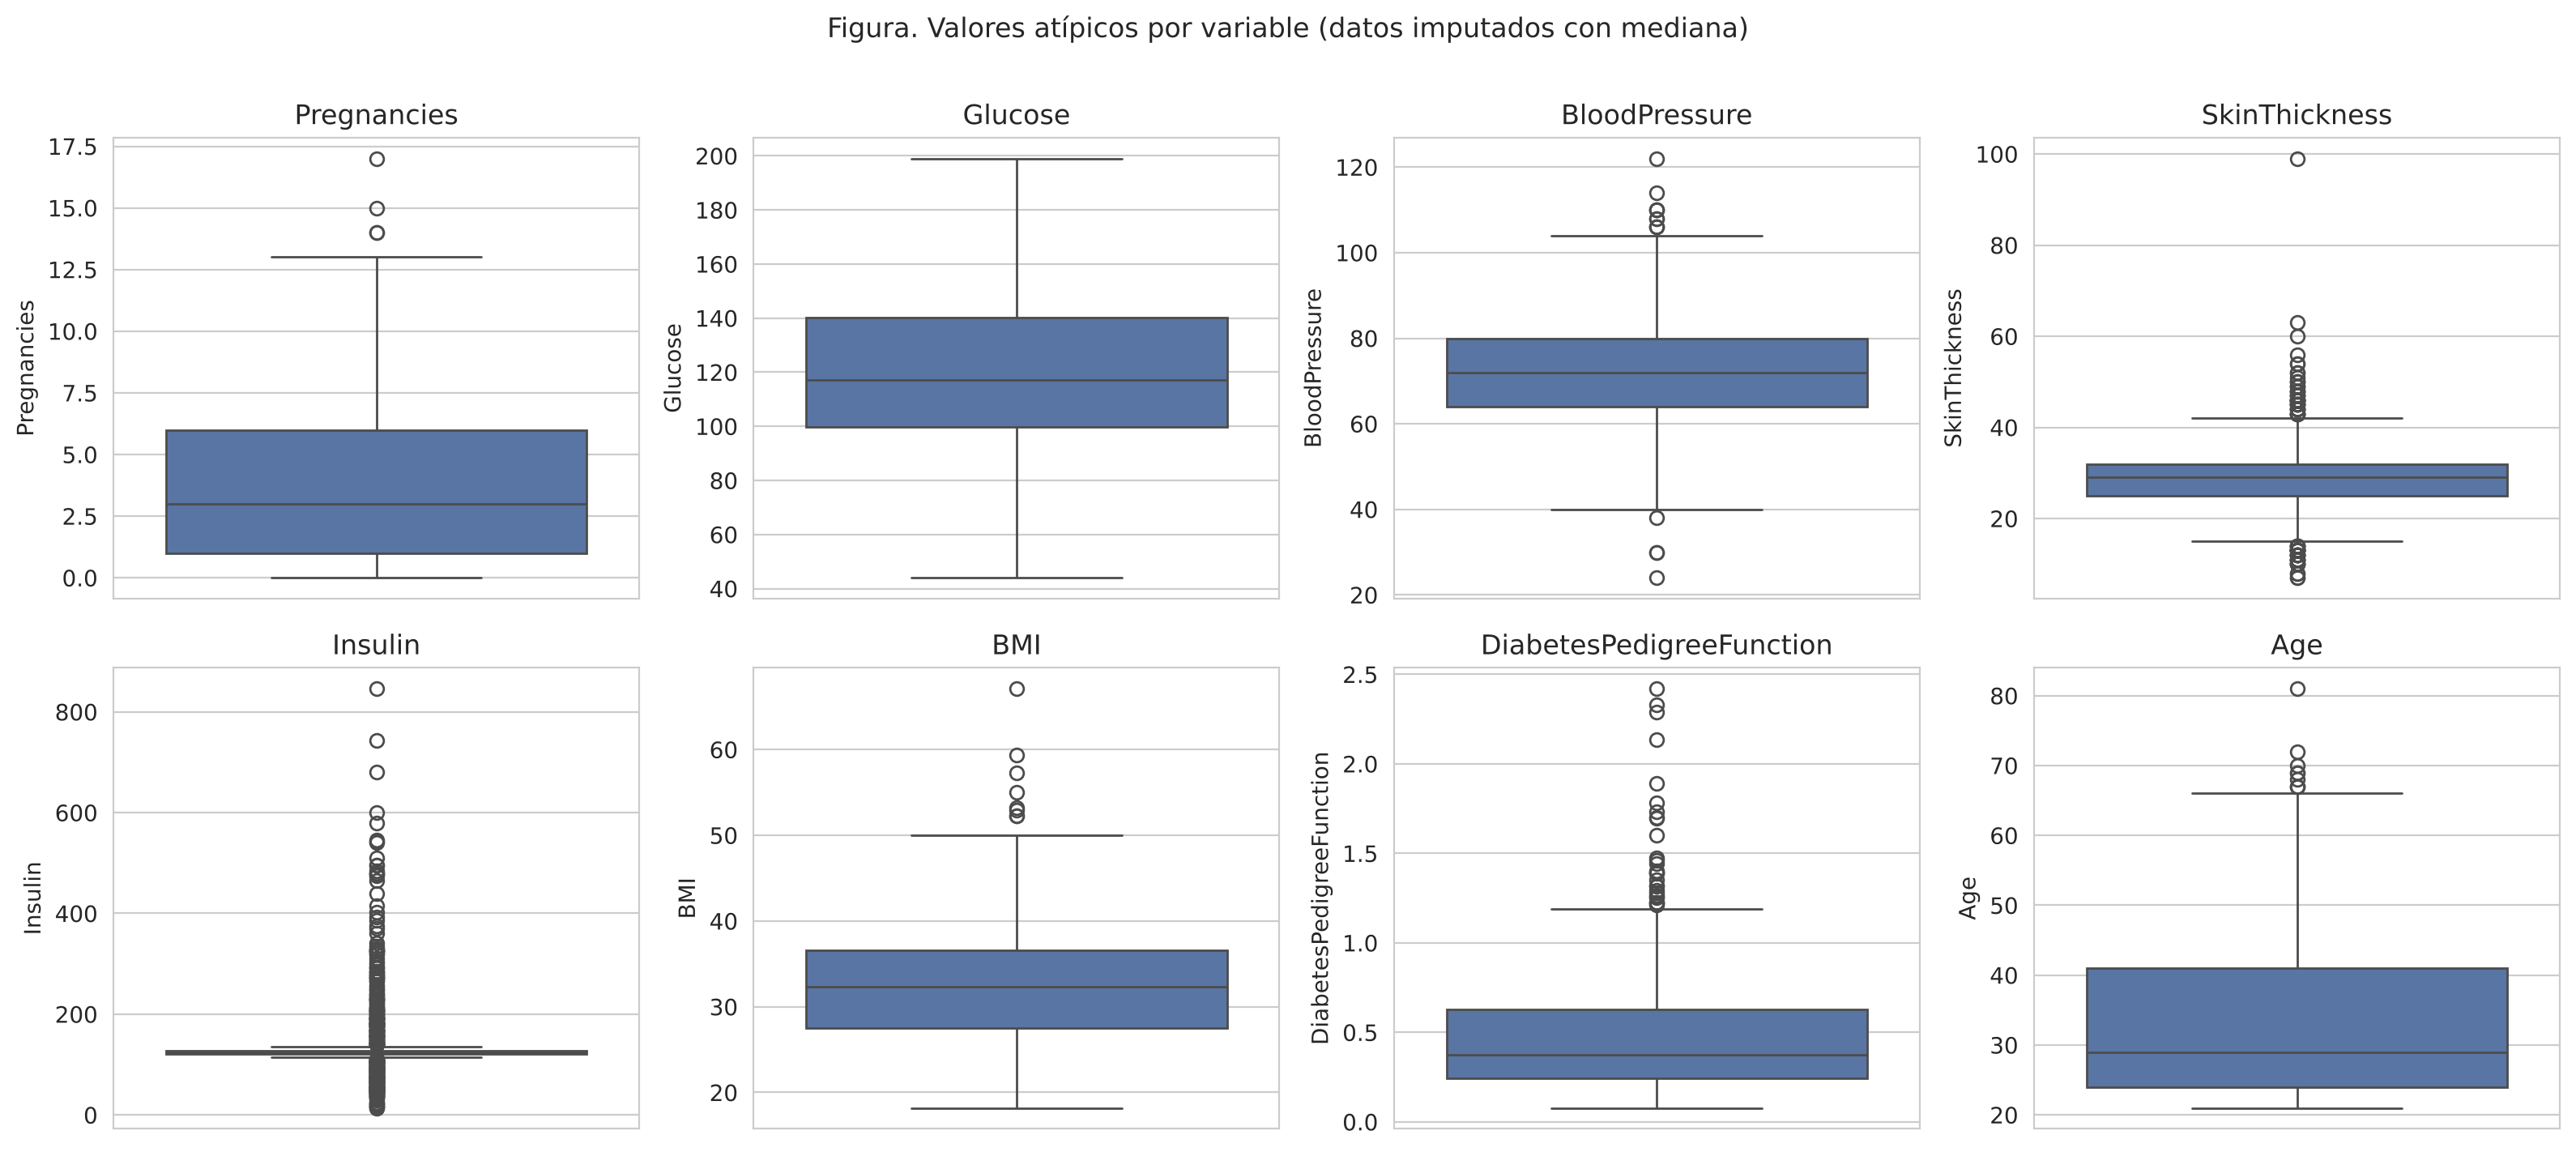

In [14]:
num_cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
def n_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
print(pd.Series({c: n_outliers(df_limpio[c]) for c in num_cols}, name="n_atípicos (regla IQR)"))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(y=df_limpio[col], ax=ax, color="#4C72B0")
    ax.set_title(col)
fig.suptitle("Figura. Valores atípicos por variable (datos imputados con mediana)", y=1.01)
plt.tight_layout()
plt.show()

**Decisión:** no se eliminan registros atípicos. Valores como `Insulin` alta o `Pregnancies` elevado son clínicamente posibles; eliminarlos reduciría la muestra (768 registros) y podría quitar justamente casos de riesgo. Los modelos de árbol son robustos a estos valores y en regresión logística se usa escalamiento. Parte de los «atípicos» de `Insulin` y `SkinThickness` se debe al pico artificial creado por la imputación con mediana.

### 9.4 Distribución por diagnóstico

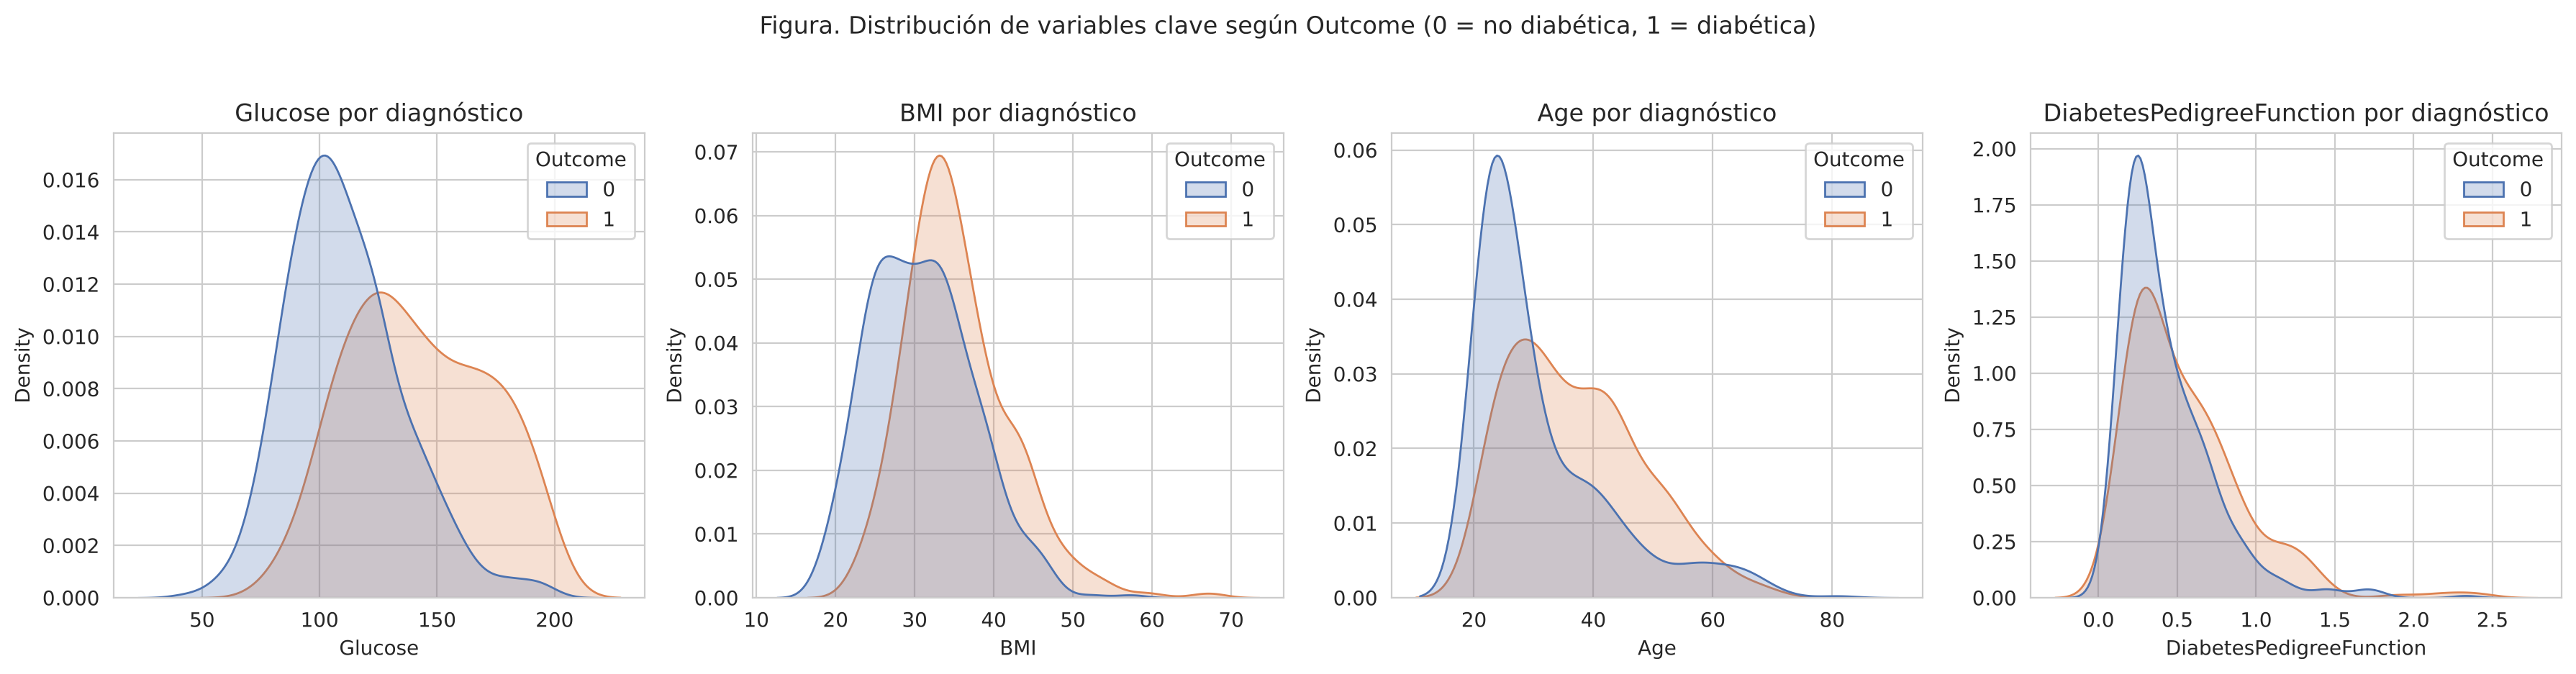

In [15]:
vars_kde = ["Glucose", "BMI", "Age", "DiabetesPedigreeFunction"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, vars_kde):
    sns.kdeplot(data=df_limpio, x=col, hue="Outcome", common_norm=False, fill=True, ax=ax,
                palette=["#4C72B0", "#DD8452"])
    ax.set_title(f"{col} por diagnóstico")
fig.suptitle("Figura. Distribución de variables clave según Outcome (0 = no diabética, 1 = diabética)", y=1.03)
plt.tight_layout()
plt.show()

**Interpretación:** la glucosa separa mejor a las dos clases (la curva de las diabéticas se desplaza a la derecha); IMC, edad y antecedente familiar muestran diferencias menores con solapamiento amplio. Son asociaciones, no relaciones causales.

### 9.5 Tasa de diabetes por grupos de edad e IMC

              n  % con diabetes
Grupo_edad                     
21-30       417            21.6
31-40       157            48.4
41-50       113            56.6
51+          81            46.9 

                 n  % con diabetes
Categoria_IMC                     
<25            112             6.2
25-30          180            24.4
>30            476            45.6 



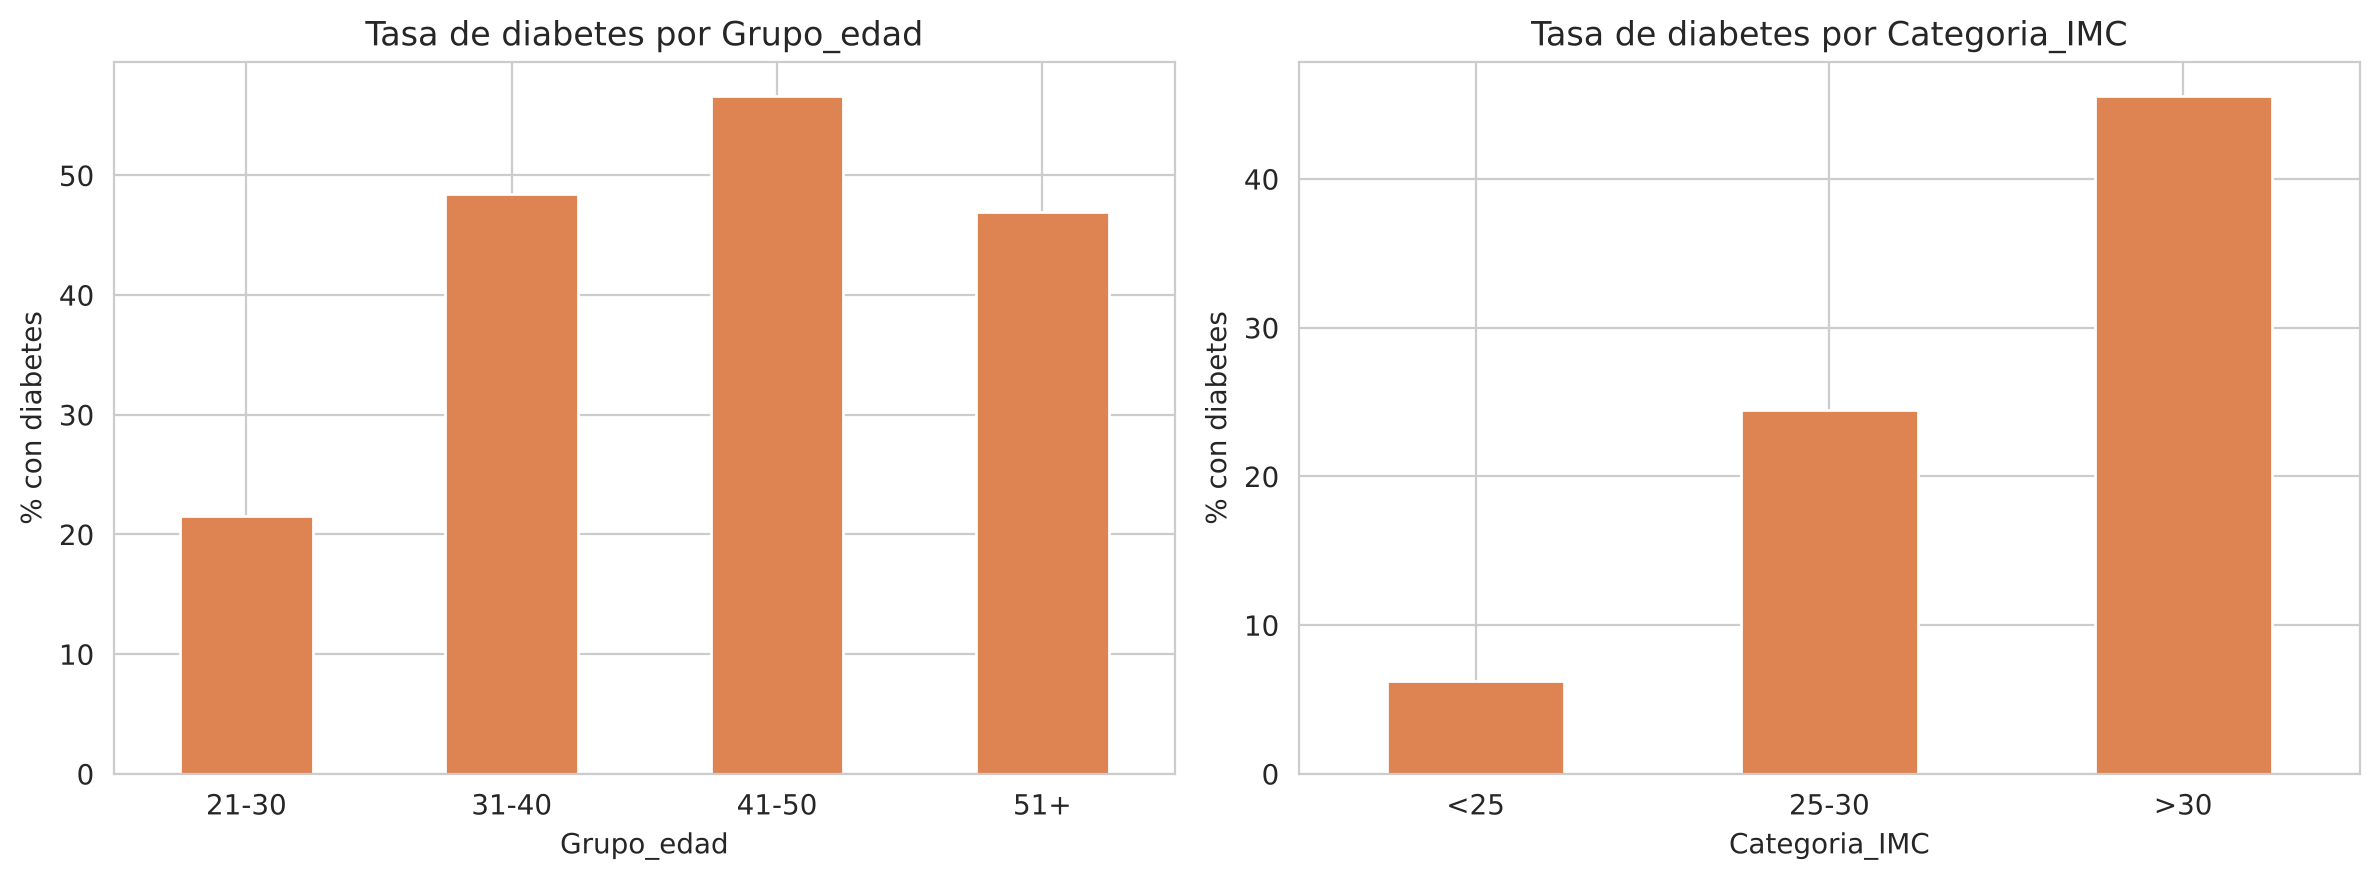

In [16]:
tmp = df_limpio.copy()
tmp["Grupo_edad"] = pd.cut(tmp["Age"], [20, 30, 40, 50, 90], labels=["21-30", "31-40", "41-50", "51+"])
tmp["Categoria_IMC"] = pd.cut(tmp["BMI"], [0, 25, 30, 100], labels=["<25", "25-30", ">30"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col in zip(axes, ["Grupo_edad", "Categoria_IMC"]):
    tasa = tmp.groupby(col, observed=True)["Outcome"].mean() * 100
    tasa.plot(kind="bar", ax=ax, color="#DD8452", rot=0)
    ax.set_ylabel("% con diabetes"); ax.set_title(f"Tasa de diabetes por {col}")
    tam = tmp.groupby(col, observed=True).size()
    print(pd.DataFrame({"n": tam, "% con diabetes": tasa.round(1)}).to_string(), "\n")
plt.tight_layout()
plt.show()

**Interpretación:** la proporción de pacientes diabéticas aumenta con el IMC (6,2 % con IMC <25 frente a 45,6 % con IMC >30) y es mucho menor en el grupo de 21-30 años (21,6 %) que en los de 31-50 años (48,4 % y 56,6 %); en el grupo de 51+ baja ligeramente (46,9 %); es el grupo más pequeño (81 pacientes), por lo que su tasa es menos estable. Esto respalda el uso de ambas como predictoras, aunque son asociaciones y no implican causalidad.

### 9.6 Correlaciones con la variable objetivo

In [17]:
corr_obj = df_limpio.corr()["Outcome"].drop("Outcome").sort_values(ascending=False)
print(corr_obj.round(3))
print()
c = df_limpio.drop(columns="Outcome").corr()
pares = (c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack().sort_values(ascending=False))
print("Pares de predictoras más correlacionados:")
print(pares.head(4).round(3))

Glucose                     0.493
BMI                         0.312
Age                         0.238
Pregnancies                 0.222
SkinThickness               0.215
Insulin                     0.204
DiabetesPedigreeFunction    0.174
BloodPressure               0.166
Name: Outcome, dtype: float64

Pares de predictoras más correlacionados:
Pregnancies    Age        0.544
SkinThickness  BMI        0.543
Glucose        Insulin    0.419
BloodPressure  Age        0.325
dtype: float64


**Interpretación:** `Glucose` es la variable más asociada a `Outcome`. Entre predictoras no hay correlaciones extremas (la mayor es moderada), por lo que no se anticipa multicolinealidad grave, aunque `Age`–`Pregnancies` y `SkinThickness`–`BMI` están moderadamente relacionadas.

## 10. Preparación de datos para el modelado

Versión final usada para entrenar: el dataset original (768 registros, 8 predictoras + `Outcome`), con los ceros imposibles marcados como `NaN` en las 5 columnas indicadas. **No se eliminan registros ni variables.** No hay identificadores ni variables que filtren la respuesta, aunque se debe tener en cuenta que la glucosa a 2 h forma parte de los criterios clínicos de diagnóstico (ver limitaciones).

La imputación (mediana) y el escalamiento se aplican dentro de un `Pipeline`, de modo que se aprenden **solo con el conjunto de entrenamiento**.

In [18]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay, RocCurveDisplay)

SEED = 42
X = df.drop(columns="Outcome").copy()
y = df["Outcome"]
X[cols_sin_ceros_validos] = X[cols_sin_ceros_validos].replace(0, np.nan)   # marcar faltantes (no aprende nada de los datos)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("% diabéticas en entrenamiento:", round(y_train.mean() * 100, 1), "| en prueba:", round(y_test.mean() * 100, 1))

Entrenamiento: (614, 8) | Prueba: (154, 8)
% diabéticas en entrenamiento: 34.9 | en prueba: 35.1


Se usa una división 80/20 **estratificada** por `Outcome` para conservar la proporción de clases en ambos conjuntos, con semilla fija para reproducibilidad.

## 11. Selección y entrenamiento de modelos

| Modelo | Por qué se eligió |
|---|---|
| **Regresión logística** (con escalamiento) | Línea base interpretable para clasificación binaria; los coeficientes indican dirección e importancia relativa. |
| **Árbol de decisión** (`max_depth=4`) | Captura relaciones no lineales/interacciones y es fácil de interpretar. Se fija una profundidad máxima de 4 solo para evitar sobreajuste extremo; estos son los **modelos base del corte 2**, sin búsqueda de hiperparámetros; la versión ajustada se presenta en la sección 12.6. |
| **Random forest** (200 árboles) | Modelo de conjunto adicional para contrastar contra los modelos simples. |

Los tres usan `class_weight="balanced"` para compensar el desbalance (~65/35).

In [19]:
def prep(scale):
    pasos = [("imputer", SimpleImputer(strategy="median"))]
    if scale: pasos.append(("scaler", StandardScaler()))
    return pasos

modelos = {
    "Regresión logística": Pipeline(prep(True) + [("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED))]),
    "Árbol de decisión":   Pipeline(prep(False) + [("clf", DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=SEED))]),
    "Random forest":       Pipeline(prep(False) + [("clf", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED))]),
}
for nombre, m in modelos.items():
    m.fit(X_train, y_train)
print("Modelos entrenados:", list(modelos))

Modelos entrenados: ['Regresión logística', 'Árbol de decisión', 'Random forest']


## 12. Evaluación e interpretación

In [20]:
filas, preds, probas = [], {}, {}
for nombre, m in modelos.items():
    p = m.predict(X_test); pr = m.predict_proba(X_test)[:, 1]
    preds[nombre], probas[nombre] = p, pr
    filas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "F1": f1_score(y_test, p),
        "AUC-ROC": roc_auc_score(y_test, pr),
        "F1 entrenamiento": f1_score(y_train, m.predict(X_train)),
    })
tabla = pd.DataFrame(filas).set_index("Modelo").round(3)
tabla

,Accuracy,Precision,Recall,F1,AUC-ROC,F1 entrenamiento
Modelo,,,,,,
Regresión logística,0.734,0.603,0.704,0.650,0.813,0.673
Árbol de decisión,0.708,0.556,0.833,0.667,0.767,0.734
Random forest,0.740,0.652,0.556,0.600,0.812,1.000


*Precision, Recall y F1 se calculan para la clase positiva (1 = diabética).* La columna «F1 entrenamiento» permite comparar entrenamiento vs. prueba para detectar sobreajuste.

In [21]:
for nombre in modelos:
    print("=" * 60); print(nombre)
    print(classification_report(y_test, preds[nombre], target_names=["No diabética (0)", "Diabética (1)"], digits=3))

Regresión logística
                  precision    recall  f1-score   support

No diabética (0)      0.824     0.750     0.785       100
   Diabética (1)      0.603     0.704     0.650        54

        accuracy                          0.734       154
       macro avg      0.714     0.727     0.717       154
    weighted avg      0.747     0.734     0.738       154

Árbol de decisión
                  precision    recall  f1-score   support

No diabética (0)      0.877     0.640     0.740       100
   Diabética (1)      0.556     0.833     0.667        54

        accuracy                          0.708       154
       macro avg      0.716     0.737     0.703       154
    weighted avg      0.764     0.708     0.714       154

Random forest
                  precision    recall  f1-score   support

No diabética (0)      0.778     0.840     0.808       100
   Diabética (1)      0.652     0.556     0.600        54

        accuracy                          0.740       154
       macro

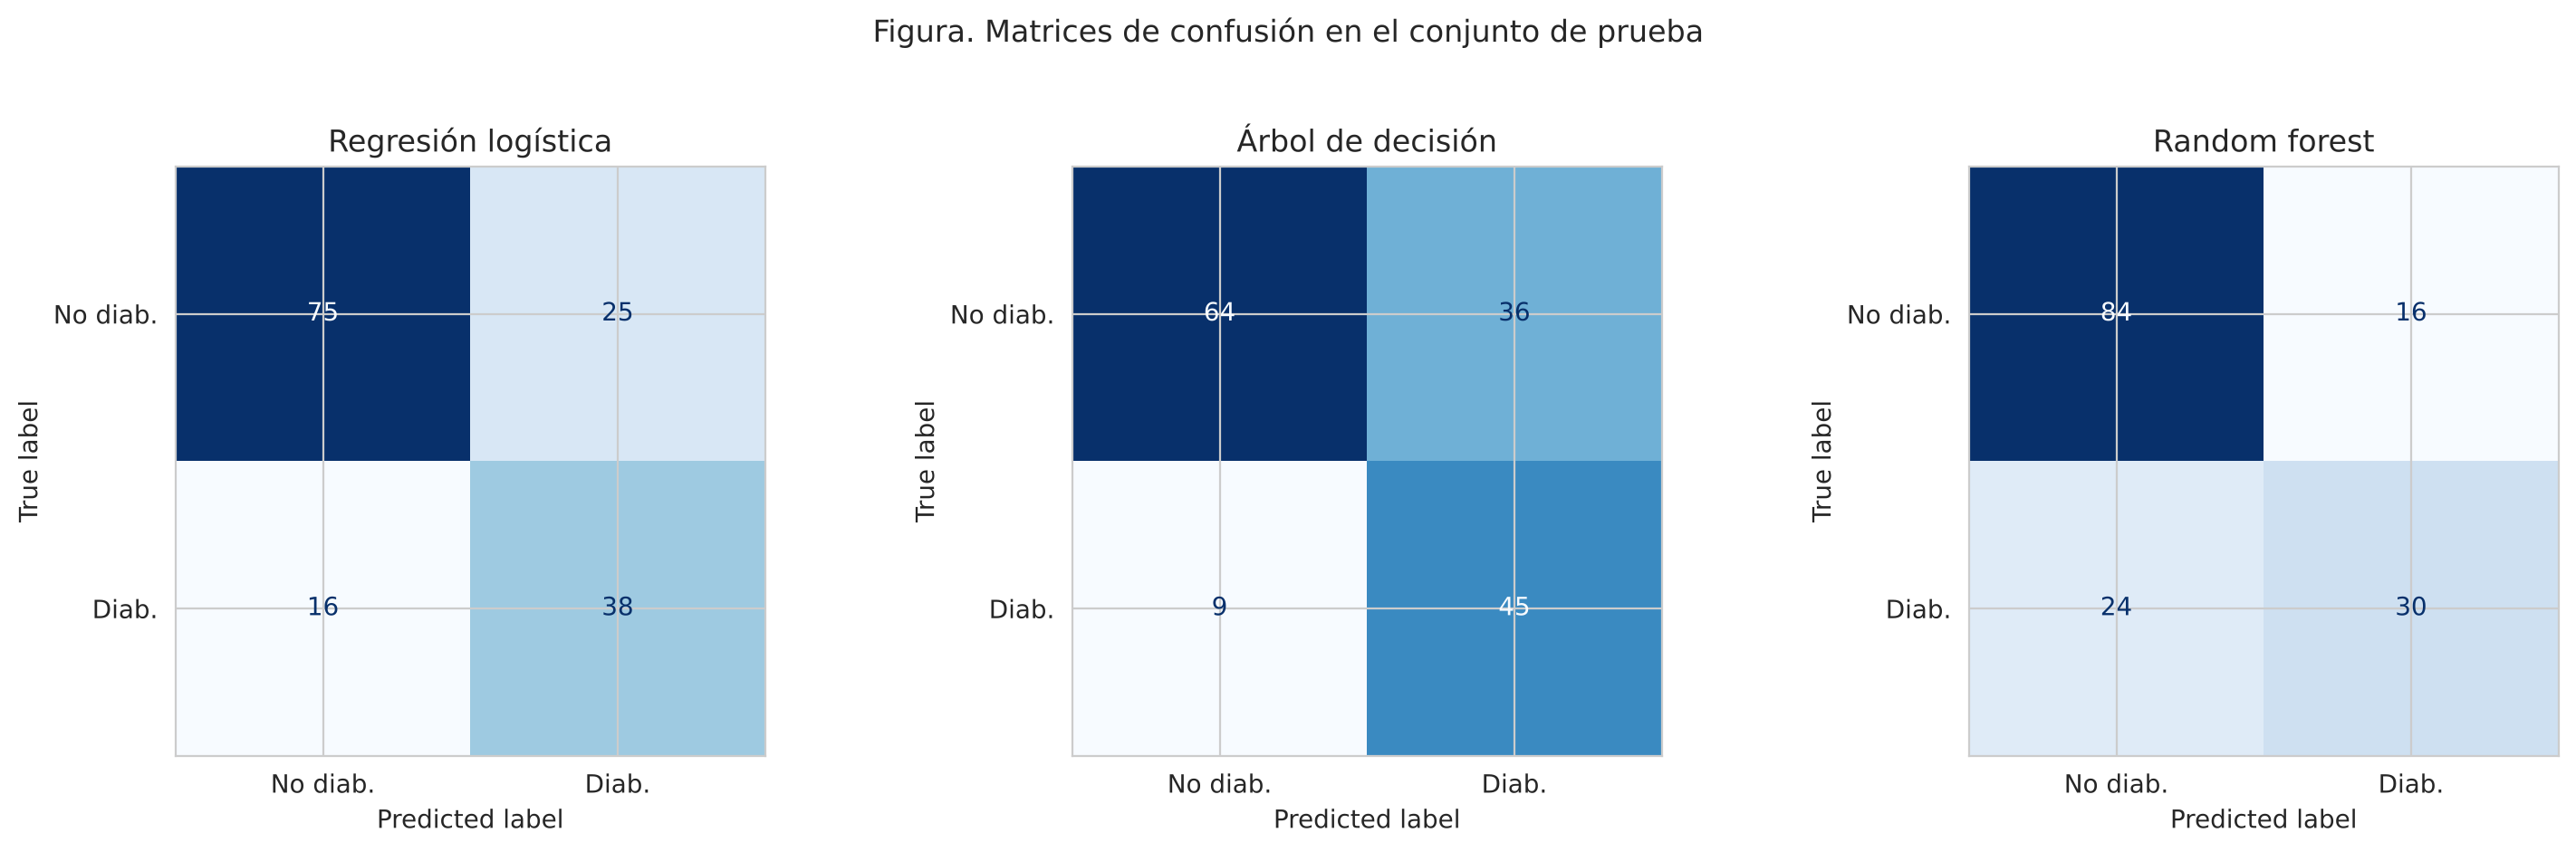

,VP,VN,FP (falsa alarma),FN (diabética no detectada)
Modelo,,,,
Regresión logística,38,75,25,16
Árbol de decisión,45,64,36,9
Random forest,30,84,16,24


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, nombre in zip(axes, modelos):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[nombre], display_labels=["No diab.", "Diab."],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(nombre)
fig.suptitle("Figura. Matrices de confusión en el conjunto de prueba", y=1.03)
plt.tight_layout()
plt.show()

errores = []
for nombre in modelos:
    tn, fp, fn, tp = confusion_matrix(y_test, preds[nombre]).ravel()
    errores.append({"Modelo": nombre, "VP": tp, "VN": tn, "FP (falsa alarma)": fp, "FN (diabética no detectada)": fn})
pd.DataFrame(errores).set_index("Modelo")

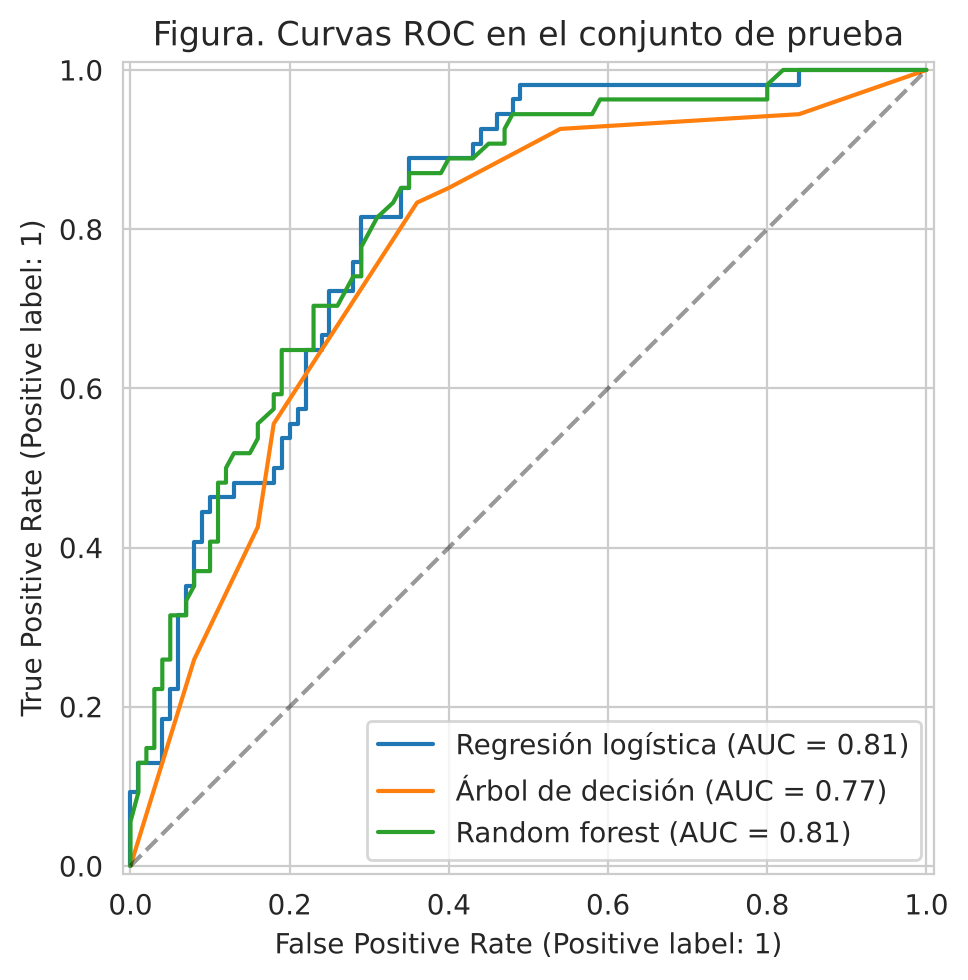

In [23]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for nombre in modelos:
    RocCurveDisplay.from_predictions(y_test, probas[nombre], name=nombre, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=.4)
ax.set_title("Figura. Curvas ROC en el conjunto de prueba")
plt.tight_layout()
plt.show()

### 12.1 Validación cruzada (5 pliegues, solo sobre entrenamiento)

In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
filas_cv = []
for nombre, m in modelos.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=["accuracy", "recall", "f1", "roc_auc"])
    filas_cv.append({"Modelo": nombre,
                     "Accuracy": f"{r['test_accuracy'].mean():.3f} ± {r['test_accuracy'].std():.3f}",
                     "Recall": f"{r['test_recall'].mean():.3f} ± {r['test_recall'].std():.3f}",
                     "F1": f"{r['test_f1'].mean():.3f} ± {r['test_f1'].std():.3f}",
                     "AUC-ROC": f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}"})
tabla_cv = pd.DataFrame(filas_cv).set_index("Modelo")
tabla_cv

,Accuracy,Recall,F1,AUC-ROC
Modelo,,,,
Regresión logística,0.762 ± 0.011,0.701 ± 0.039,0.672 ± 0.013,0.844 ± 0.016
Árbol de decisión,0.707 ± 0.032,0.748 ± 0.118,0.637 ± 0.052,0.786 ± 0.027
Random forest,0.769 ± 0.028,0.589 ± 0.025,0.640 ± 0.036,0.822 ± 0.027


La validación cruzada muestra si el desempeño es estable entre distintas particiones; con solo 154 pacientes en prueba, una única división puede ser optimista o pesimista.

### 12.2 ¿Qué variables usa cada modelo?

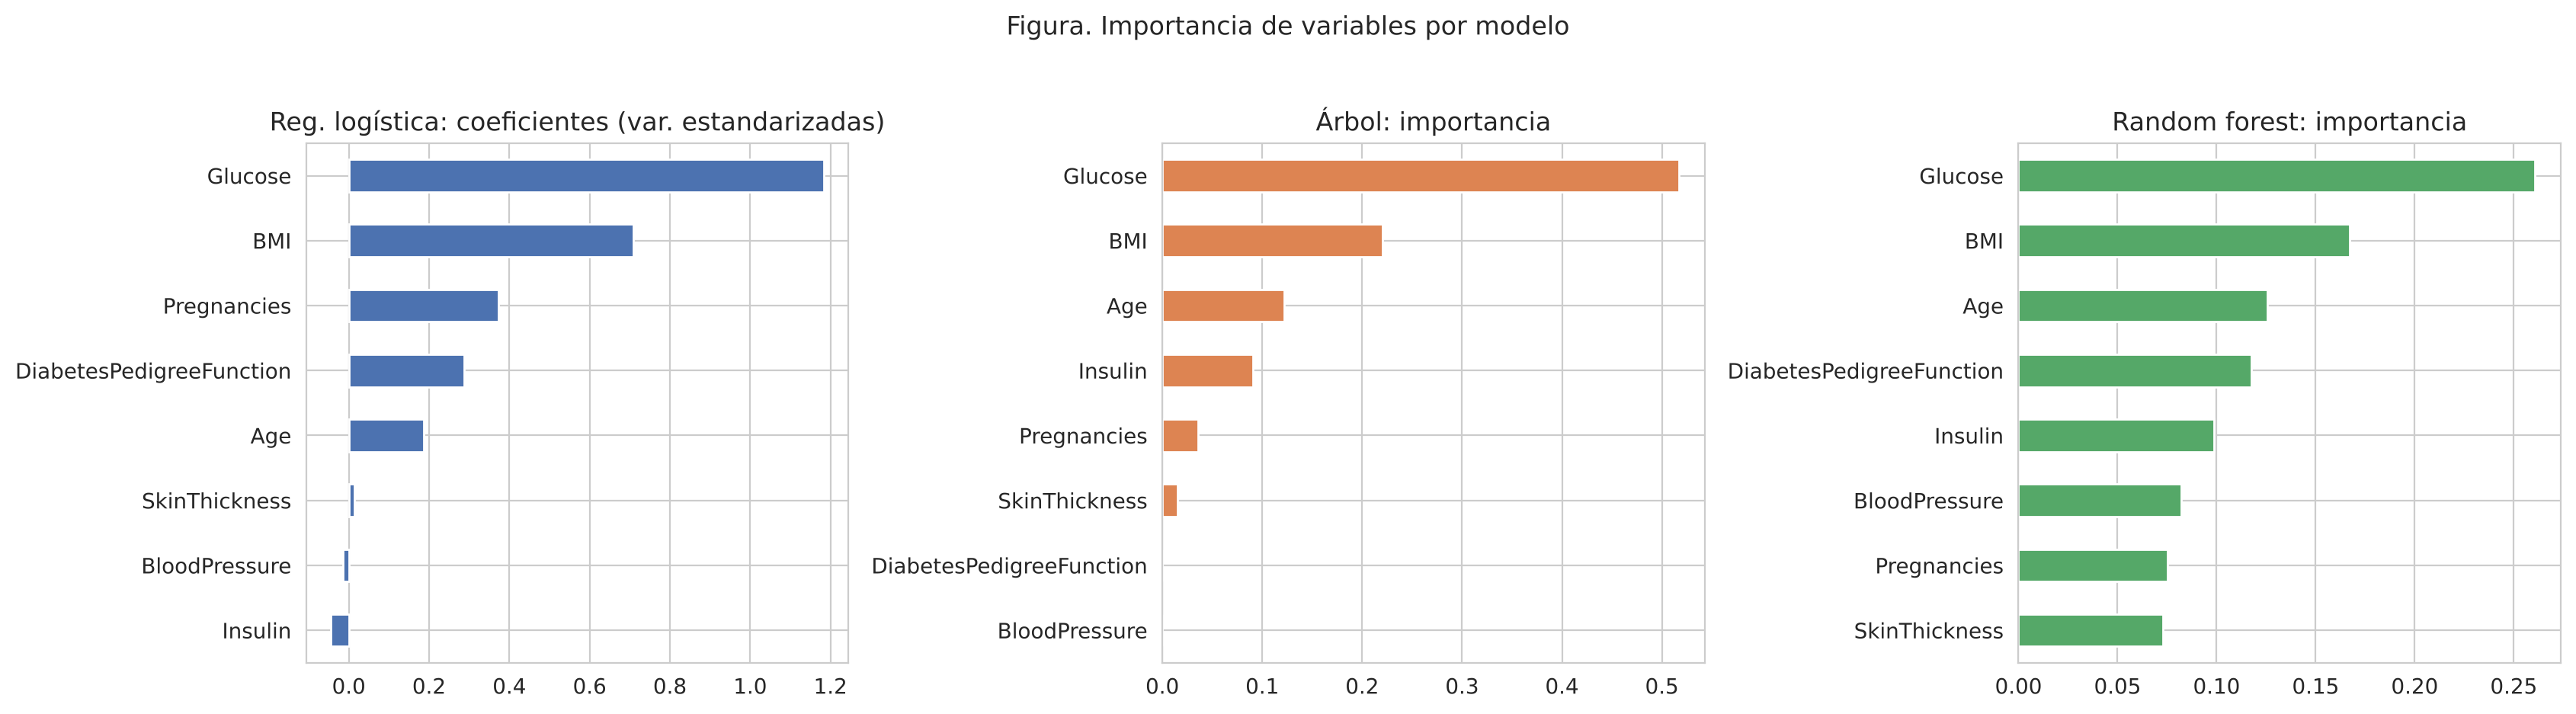

In [25]:
coef = pd.Series(modelos["Regresión logística"].named_steps["clf"].coef_[0], index=X.columns).sort_values()
imp_tree = pd.Series(modelos["Árbol de decisión"].named_steps["clf"].feature_importances_, index=X.columns).sort_values()
imp_rf = pd.Series(modelos["Random forest"].named_steps["clf"].feature_importances_, index=X.columns).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
coef.plot(kind="barh", ax=axes[0], color="#4C72B0"); axes[0].set_title("Reg. logística: coeficientes (var. estandarizadas)")
imp_tree.plot(kind="barh", ax=axes[1], color="#DD8452"); axes[1].set_title("Árbol: importancia")
imp_rf.plot(kind="barh", ax=axes[2], color="#55A868"); axes[2].set_title("Random forest: importancia")
fig.suptitle("Figura. Importancia de variables por modelo", y=1.03)
plt.tight_layout()
plt.show()

*Los coeficientes e importancias describen asociaciones aprendidas por el modelo, no efectos causales.*

### 12.3 Análisis de errores de los modelos base (corte 2)

In [26]:
# Pacientes diabéticas no detectadas (falsos negativos) vs. detectadas, para el modelo con mayor recall
mejor_recall = tabla["Recall"].idxmax()
test = X_test.copy(); test["real"] = y_test; test["pred"] = preds[mejor_recall]
fn = test[(test.real == 1) & (test.pred == 0)]
vp = test[(test.real == 1) & (test.pred == 1)]
print(f"Modelo con mayor recall: {mejor_recall} → FN = {len(fn)}, VP = {len(vp)}")
print(pd.DataFrame({"FN (no detectadas)": fn[["Glucose", "BMI", "Age"]].mean(),
                    "VP (detectadas)": vp[["Glucose", "BMI", "Age"]].mean()}).round(1))

Modelo con mayor recall: Árbol de decisión → FN = 9, VP = 45
         FN (no detectadas)  VP (detectadas)
Glucose               119.4            144.1
BMI                    35.0             34.9
Age                    27.9             38.0


In [27]:
import json
resultados = {
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "pct_diab_train": round(float(y_train.mean() * 100), 1), "pct_diab_test": round(float(y_test.mean() * 100), 1),
    "metricas": tabla.reset_index().to_dict(orient="records"),
    "cv": tabla_cv.reset_index().to_dict(orient="records"),
    "errores": pd.DataFrame(errores).to_dict(orient="records"),
    "corr_obj": corr_obj.round(3).to_dict(),
    "importancia_rf": imp_rf.sort_values(ascending=False).round(3).to_dict(),
    "coef_lr": coef.sort_values(ascending=False).round(3).to_dict(),
}
with open("resultados_modelos.json", "w") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=1, default=int)
print("Resultados guardados en resultados_modelos.json (usados en el informe)")

Resultados guardados en resultados_modelos.json (usados en el informe)


### Cambios frente al segundo avance (corte 3)

| Cambio | Justificación |
|---|---|
| Se agrega una **línea base** (`DummyClassifier`). | Permite saber cuánto aporta realmente un modelo frente a no aprender nada (sección 12.4). |
| La imputación pasa de **mediana** a **mediana + indicador de faltante** (dentro del `Pipeline`). | Fue la que obtuvo mayor F1 medio en validación cruzada entre cuatro alternativas (sección 12.5). La imputación por grupo según `Outcome` se descartó por usar la variable objetivo (fuga de información). |
| Los tres modelos se **ajustan con `GridSearchCV`** (F1, 5 pliegues) y se reporta validación cruzada anidada. | En el corte 2 no se había ajustado ningún hiperparámetro (sección 12.6). |
| El **modelo final** pasa de la regresión logística base a un **random forest ajustado**. | Mayor F1 en validación cruzada (0,702 frente a 0,695) y en la validación anidada; la diferencia es pequeña, ver 12.6 y 12.8. |
| Se **evalúa el umbral de decisión** y se conserva 0,5. | La mejora posible del F1 (0,003) es menor que la variabilidad entre pliegues (0,006); ver 12.7. |
| Se agrega **análisis de errores del modelo final** y se guardan pipeline, columnas y umbral para la aplicación. | La aplicación debe cargar exactamente el pipeline evaluado (secciones 12.9 y 12b). |

**Lo que no cambió:** el dataset, la pregunta de investigación, la variable objetivo, la división 80/20 estratificada con semilla 42 y la métrica principal (F1 de la clase positiva). **Importante:** como el modelo final cambió, el archivo `modelo_diabetes.joblib` del repositorio y la aplicación deben actualizarse con los generados en la sección 12b.

## 12.4 Revisión del rendimiento: métrica principal por debajo de 0,70

La métrica principal del proyecto es el **F1-score de la clase positiva (diabética)**, porque el accuracy se ve inflado por el desbalance y porque en un tamizaje importa tanto no dejar pacientes sin detectar (recall) como no generar demasiadas falsas alarmas (precision). En los modelos base del corte 2 el F1 quedó por debajo de 0,70, por lo que se documenta una revisión ordenada. Los ajustes se evalúan **solo con validación cruzada sobre entrenamiento**; el conjunto de prueba se usa una única vez al final (sección 12.8) para no inflar artificialmente la métrica.

Primero se fija una **línea base** para saber cuánto aporta realmente un modelo:

In [28]:
import os, warnings
os.environ["PYTHONWARNINGS"] = "ignore"; warnings.filterwarnings("ignore")
from sklearn.dummy import DummyClassifier
from sklearn.impute import KNNImputer
from sklearn.model_selection import GridSearchCV, cross_val_score, cross_val_predict

def metricas(y_real, y_pred, y_prob=None):
    d = {"Accuracy": accuracy_score(y_real, y_pred),
         "Precision": precision_score(y_real, y_pred, zero_division=0),
         "Recall": recall_score(y_real, y_pred),
         "F1": f1_score(y_real, y_pred)}
    if y_prob is not None:
        d["AUC-ROC"] = roc_auc_score(y_real, y_prob)
    return d

filas_base = []
for estrategia in ["most_frequent", "stratified"]:
    d = DummyClassifier(strategy=estrategia, random_state=SEED).fit(X_train, y_train)
    filas_base.append({"Modelo": f"Línea base ({estrategia})", **metricas(y_test, d.predict(X_test))})
filas_base.append({"Modelo": "Regresión logística (corte 2, umbral 0,5)",
                   **metricas(y_test, preds["Regresión logística"], probas["Regresión logística"])})
tabla_base = pd.DataFrame(filas_base).set_index("Modelo").round(3)
tabla_base

,Accuracy,Precision,Recall,F1,AUC-ROC
Modelo,,,,,
Línea base (most_frequent),0.649,0.000,0.000,0.000,NaN
Línea base (stratified),0.597,0.417,0.370,0.392,NaN
"Regresión logística (corte 2, umbral 0,5)",0.734,0.603,0.704,0.650,0.813


**Interpretación:** predecir siempre «no diabética» da un accuracy de 0,649 pero un recall de 0 (no detecta a ninguna paciente), por eso el accuracy no sirve como criterio único. La línea base aleatoria estratificada llega a un F1 de 0,392. La regresión logística del corte 2 mejora claramente sobre ambas (F1 = 0,650; recall = 0,704), pero su F1 queda por debajo de 0,70, el valor de referencia para revisar el proceso. Ese valor es una señal de revisión y no una garantía de calidad; por eso se revisan los pasos del proceso que podían estar limitando el rendimiento (imputación, hiperparámetros y umbral) sin modificar la partición ni la métrica para obtener un número más alto.

## 12.5 Comparación de estrategias de imputación

Se compara la imputación dentro del pipeline (siempre ajustada solo con los datos de cada pliegue de entrenamiento) usando la regresión logística como modelo de referencia. La imputación **por grupo según `Outcome`** que se había considerado en el primer avance se **descarta**: usaría la variable objetivo para rellenar los predictores y esa información no existe cuando se predice una paciente nueva (fuga de información).

In [29]:
imputadores = {
    "Mediana": lambda: SimpleImputer(strategy="median"),
    "Media": lambda: SimpleImputer(strategy="mean"),
    "Mediana + indicador de faltante": lambda: SimpleImputer(strategy="median", add_indicator=True),
    "KNN (k=5)": lambda: KNNImputer(n_neighbors=5),
}

def pipe_lr(imp):
    return Pipeline([("imputer", imp), ("scaler", StandardScaler()),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED))])

filas_imp, f1_medio = [], {}
for nombre, fabrica in imputadores.items():
    r = cross_validate(pipe_lr(fabrica()), X_train, y_train, cv=cv, scoring=["precision", "recall", "f1", "roc_auc"])
    f1_medio[nombre] = r["test_f1"].mean()
    filas_imp.append({"Imputación": nombre,
                      **{m: f"{r['test_' + k].mean():.3f} ± {r['test_' + k].std():.3f}"
                         for m, k in [("Precision", "precision"), ("Recall", "recall"), ("F1", "f1"), ("AUC-ROC", "roc_auc")]}})

IMPUTADOR_ELEGIDO = max(f1_medio, key=f1_medio.get)
print("Imputación elegida (mayor F1 medio en validación cruzada):", IMPUTADOR_ELEGIDO)
pd.DataFrame(filas_imp).set_index("Imputación")

Imputación elegida (mayor F1 medio en validación cruzada): Mediana + indicador de faltante


,Precision,Recall,F1,AUC-ROC
Imputación,,,,
Mediana,0.649 ± 0.026,0.701 ± 0.039,0.672 ± 0.013,0.844 ± 0.016
Media,0.650 ± 0.025,0.706 ± 0.042,0.675 ± 0.013,0.845 ± 0.015
Mediana + indicador de faltante,0.662 ± 0.032,0.734 ± 0.037,0.695 ± 0.017,0.839 ± 0.023
KNN (k=5),0.643 ± 0.036,0.706 ± 0.045,0.671 ± 0.016,0.843 ± 0.016


**Interpretación:** la mediana, la media y KNN dan resultados prácticamente iguales (F1 entre 0,671 y 0,675, con desviaciones de 0,013 a 0,016). Agregar un **indicador de faltante** sube el F1 medio a 0,695 y el recall a 0,734, aunque el AUC-ROC baja ligeramente (0,839 frente a 0,844). La mejora de 0,02 en F1 es pequeña pero mayor que la desviación entre pliegues. Los porcentajes de ceros son similares entre clases (por ejemplo, `Insulin`: 47,2 % en no diabéticas y 51,5 % en diabéticas, sección 9.2), por lo que no se afirma que la ausencia del dato esté asociada al diagnóstico; el indicador puede aportar algo de información sobre cuáles mediciones se realizaron, pero esa ganancia debe tomarse con cautela. Se adopta esta imputación porque cumple el criterio definido (mayor F1 medio en validación cruzada).

## 12.6 Ajuste de hiperparámetros

Se ajusta cada modelo con `GridSearchCV` (5 pliegues estratificados, métrica F1, solo sobre entrenamiento) usando la imputación elegida en 12.5. Como el mejor puntaje de una búsqueda es optimista (se escogió justamente por ser el mejor), se reporta además una **validación cruzada anidada** (semilla distinta) que estima el F1 del procedimiento completo de búsqueda.

In [30]:
imp_fabrica = imputadores[IMPUTADOR_ELEGIDO]

def mk(clf):
    return Pipeline([("imputer", imp_fabrica()), ("clf", clf)])

espacios = {
    "Regresión logística": (pipe_lr(imp_fabrica()), {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}),
    "Árbol de decisión": (mk(DecisionTreeClassifier(class_weight="balanced", random_state=SEED)),
                          {"clf__max_depth": [2, 3, 4, 5, 6], "clf__min_samples_leaf": [1, 5, 10, 20]}),
    "Random forest": (mk(RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED)),
                      {"clf__max_depth": [3, 5, 7, None], "clf__min_samples_leaf": [1, 3, 5, 10], "clf__max_features": ["sqrt", 0.5]}),
}
cv_anidada = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)

busquedas, filas_aj = {}, []
for nombre, (pipe, grid) in espacios.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=-1).fit(X_train, y_train)
    anid = cross_val_score(GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=-1), X_train, y_train, cv=cv_anidada, scoring="f1")
    busquedas[nombre] = gs
    filas_aj.append({"Modelo": nombre,
                     "Mejores parámetros": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
                     "F1 CV (mejor combinación)": round(gs.best_score_, 3),
                     "F1 CV anidada": f"{anid.mean():.3f} ± {anid.std():.3f}"})
pd.DataFrame(filas_aj).set_index("Modelo")

,Mejores parámetros,F1 CV (mejor combinación),F1 CV anidada
Modelo,,,
Regresión logística,{'C': 1},0.695,0.661 ± 0.044
Árbol de decisión,"{'max_depth': 6, 'min_samples_leaf': 20}",0.676,0.660 ± 0.044
Random forest,"{'max_depth': 5, 'max_features': 'sqrt', 'min_...",0.702,0.683 ± 0.042


**Interpretación:** el mejor modelo según la validación cruzada es el random forest (`max_depth=5`, `max_features="sqrt"`, `min_samples_leaf=5`, 200 árboles) con F1 = 0,702. Con la validación anidada su F1 baja a 0,683 ± 0,042, lo que muestra que el mejor puntaje de la búsqueda era algo optimista. Las diferencias entre modelos (0,683 frente a 0,661 y 0,660) son menores que la desviación de la validación anidada (≈ 0,04), por lo que el F1 por sí solo no separa con claridad a los tres modelos; el random forest queda como finalista por ser el mayor en ambas validaciones. Aún no se ha usado el conjunto de prueba.

## 12.7 Selección del modelo final y del umbral de decisión

**Regla de selección (definida antes de mirar la prueba):** el modelo final es el de mayor F1 medio en validación cruzada. El umbral se elige con las probabilidades *fuera de pliegue* sobre entrenamiento (`cross_val_predict`): se adopta el umbral que maximiza el F1 solo si su mejora sobre 0,5 supera la desviación estándar del F1 entre pliegues; de lo contrario se conserva 0,5, porque una mejora menor que el ruido de la validación sería ajustar el umbral al azar.

Modelo final: Random forest | parámetros: {'clf__max_depth': 5, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5}


Umbral que maximiza F1 (fuera de pliegue): 0.44 (F1 = 0.705) | F1 en 0,50 = 0.702
Mejora = 0.003 | desviación estándar entre pliegues = 0.006
Umbral adoptado: 0.5


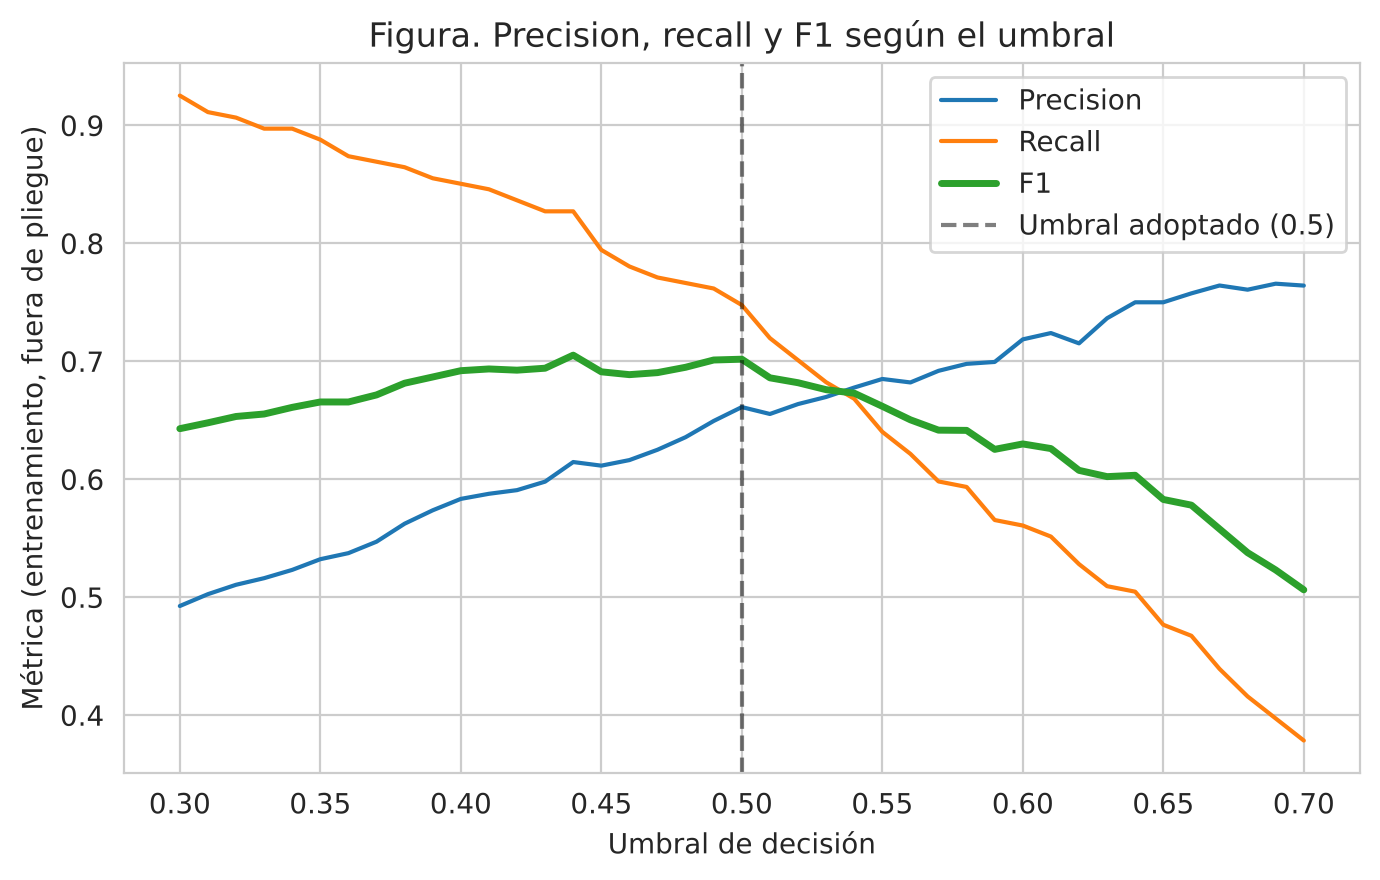

,Precision,Recall,F1,FN (de 214 diabéticas),FP
Umbral,,,,,
0.30,0.493,0.925,0.643,16,204
0.35,0.532,0.888,0.665,24,167
0.40,0.583,0.850,0.692,32,130
0.45,0.612,0.794,0.691,44,108
0.50,0.661,0.748,0.702,54,82
0.55,0.685,0.640,0.662,77,63
0.60,0.719,0.561,0.630,94,47
0.65,0.750,0.477,0.583,112,34
0.70,0.764,0.379,0.506,133,25


In [31]:
nombre_final = max(busquedas, key=lambda k: busquedas[k].best_score_)
modelo_final = busquedas[nombre_final].best_estimator_
print("Modelo final:", nombre_final, "| parámetros:", busquedas[nombre_final].best_params_)

oof = cross_val_predict(modelo_final, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
malla = np.round(np.arange(0.30, 0.701, 0.01), 2)
f1_oof = np.array([f1_score(y_train, (oof >= u).astype(int)) for u in malla])
u_max = float(malla[f1_oof.argmax()])
f1_en_05 = f1_score(y_train, (oof >= 0.5).astype(int))
sd_pliegues = cross_val_score(modelo_final, X_train, y_train, cv=cv, scoring="f1").std()
mejora = f1_oof.max() - f1_en_05
UMBRAL = u_max if mejora > sd_pliegues else 0.5
print(f"Umbral que maximiza F1 (fuera de pliegue): {u_max:.2f} (F1 = {f1_oof.max():.3f}) | F1 en 0,50 = {f1_en_05:.3f}")
print(f"Mejora = {mejora:.3f} | desviación estándar entre pliegues = {sd_pliegues:.3f}")
print("Umbral adoptado:", UMBRAL)

tabla_umbral = pd.DataFrame(
    [{"Umbral": u, "Precision": precision_score(y_train, (oof >= u).astype(int)),
      "Recall": recall_score(y_train, (oof >= u).astype(int)),
      "F1": f1_score(y_train, (oof >= u).astype(int)),
      "FN (de 214 diabéticas)": int(((oof < u) & (y_train.values == 1)).sum()),
      "FP": int(((oof >= u) & (y_train.values == 0)).sum())} for u in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]]
).set_index("Umbral").round(3)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(malla, [precision_score(y_train, (oof >= u).astype(int)) for u in malla], label="Precision")
ax.plot(malla, [recall_score(y_train, (oof >= u).astype(int)) for u in malla], label="Recall")
ax.plot(malla, f1_oof, label="F1", lw=2.5)
ax.axvline(UMBRAL, color="k", ls="--", alpha=.5, label=f"Umbral adoptado ({UMBRAL})")
ax.set_xlabel("Umbral de decisión"); ax.set_ylabel("Métrica (entrenamiento, fuera de pliegue)")
ax.set_title("Figura. Precision, recall y F1 según el umbral"); ax.legend()
plt.tight_layout(); plt.show()
tabla_umbral

**Interpretación:** el umbral que maximiza el F1 fuera de pliegue es 0,44 (F1 = 0,705), pero la mejora sobre 0,5 (0,702) es de solo 0,003, menor que la desviación estándar entre pliegues (0,006). Por la regla definida se **conserva 0,5**. La tabla muestra el costo de cada decisión: con 0,40 las diabéticas no detectadas bajan de 54 a 32 (recall de 0,748 a 0,850), pero las falsas alarmas suben de 82 a 130 (precision de 0,661 a 0,583). Si en un uso real se considerara mucho más grave dejar sin detectar a una paciente que una falsa alarma, un umbral más bajo sería una decisión razonable, pero debería fijarse por el costo clínico de cada error y no por el F1; en este proyecto académico se mantiene la regla definida de antemano.

## 12.8 Evaluación final sobre el conjunto de prueba (una sola vez)

El modelo final (con su umbral) se evalúa ahora sobre las 154 pacientes que nunca intervinieron en el entrenamiento, la imputación, el ajuste ni la elección del umbral.

F1 en entrenamiento del modelo final: 0.786 | F1 en prueba: 0.694


,Accuracy,Precision,Recall,F1,AUC-ROC
Modelo,,,,,
Línea base (most_frequent),0.649,0.000,0.000,0.000,NaN
Línea base (stratified),0.597,0.417,0.370,0.392,NaN
"Regresión logística (corte 2, umbral 0,5)",0.734,0.603,0.704,0.650,0.813
Random forest ajustado (umbral 0.5),0.753,0.614,0.796,0.694,0.823


                  precision    recall  f1-score   support

No diabética (0)      0.869     0.730     0.793       100
   Diabética (1)      0.614     0.796     0.694        54

        accuracy                          0.753       154
       macro avg      0.742     0.763     0.744       154
    weighted avg      0.780     0.753     0.758       154



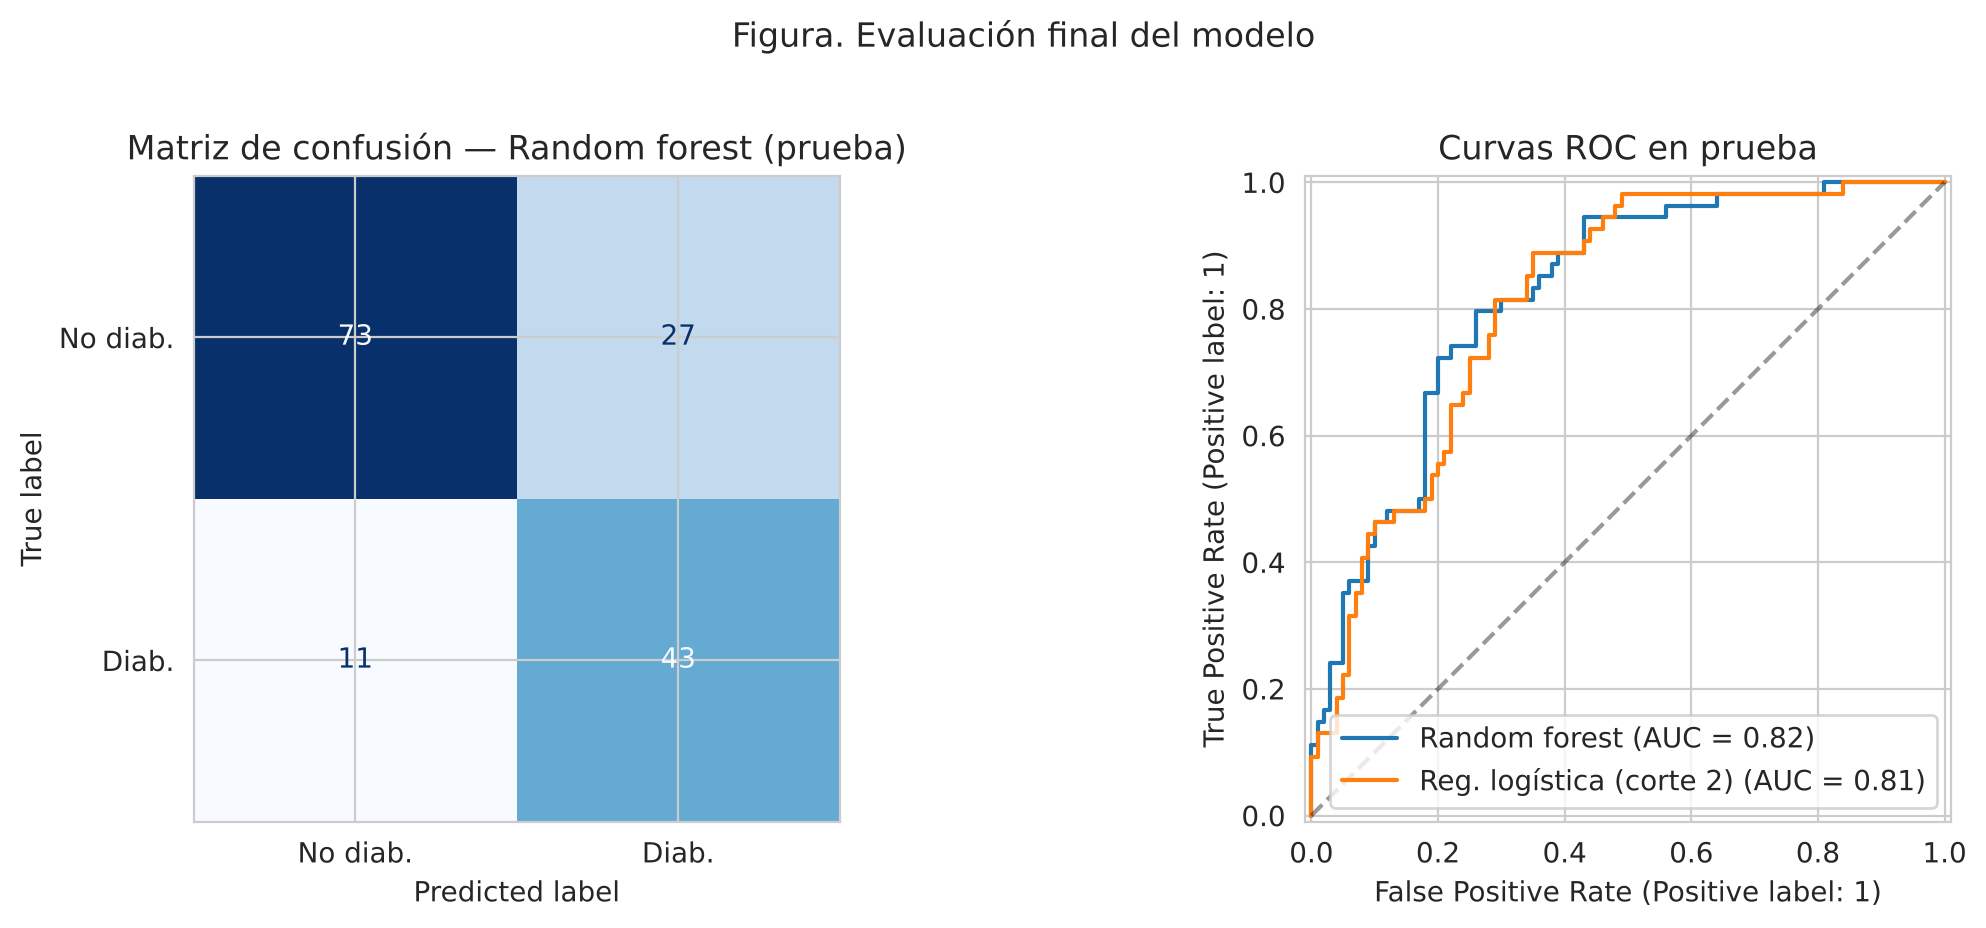

VP = 43 | VN = 73 | FP = 27 | FN = 11


In [32]:
prob_test = modelo_final.predict_proba(X_test)[:, 1]
pred_final = (prob_test >= UMBRAL).astype(int)
prob_train = modelo_final.predict_proba(X_train)[:, 1]
pred_train = (prob_train >= UMBRAL).astype(int)

filas_fin = list(filas_base)
fila_final = {"Modelo": f"{nombre_final} ajustado (umbral {UMBRAL})", **metricas(y_test, pred_final, prob_test)}
filas_fin.append(fila_final)
tabla_final = pd.DataFrame(filas_fin).set_index("Modelo").round(3)
print("F1 en entrenamiento del modelo final:", round(f1_score(y_train, pred_train), 3),
      "| F1 en prueba:", round(f1_score(y_test, pred_final), 3))
display(tabla_final)

print(classification_report(y_test, pred_final, target_names=["No diabética (0)", "Diabética (1)"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_final, display_labels=["No diab.", "Diab."], cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Matriz de confusión — {nombre_final} (prueba)")
RocCurveDisplay.from_predictions(y_test, prob_test, name=nombre_final, ax=axes[1])
RocCurveDisplay.from_predictions(y_test, probas["Regresión logística"], name="Reg. logística (corte 2)", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", alpha=.4); axes[1].set_title("Curvas ROC en prueba")
fig.suptitle("Figura. Evaluación final del modelo", y=1.02)
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred_final).ravel()
print(f"VP = {tp} | VN = {tn} | FP = {fp} | FN = {fn}")

**Interpretación:** sobre las 154 pacientes de prueba, el random forest ajustado obtiene accuracy 0,753, precision 0,614, recall 0,796, F1 0,694 y AUC-ROC 0,823. Frente a la regresión logística del corte 2 (F1 0,650; recall 0,704; AUC 0,813) mejora el recall: las diabéticas no detectadas bajan de 16 a 11 y las detectadas suben de 38 a 43, a cambio de 27 falsas alarmas (eran 25). Por clase, en las no diabéticas la precision es 0,869 y el recall 0,730; en las diabéticas la precision es 0,614 y el recall 0,796: de cada 100 mujeres sin diabetes, el modelo marca a 27 como en riesgo.

El **F1 (0,694) sigue ligeramente por debajo de 0,70**. No se modificó el proceso para superar ese valor: con solo 54 pacientes diabéticas en prueba, un caso cambia el recall en cerca de 0,019, así que 0,694 y 0,70 no son distinguibles con esta muestra. Entre entrenamiento y prueba el F1 pasa de 0,786 a 0,694, un sobreajuste moderado (el random forest sin ajustar del corte 2 tenía F1 de 1,0 en entrenamiento y 0,600 en prueba). El resultado se interpreta como una mejora modesta sobre el modelo base, no como un modelo de calidad clínica.

## 12.9 Análisis de errores y variables del modelo final

,FN (diabética no detectada),VP (diabética detectada),FP (falsa alarma),VN (no diabética bien clasificada)
n,11.0,43.0,27.0,73.0
Glucose (media),110.0,147.7,141.2,100.5
BMI (media),30.7,35.9,36.6,29.1
Age (media),28.3,38.4,36.7,28.6
% con Insulin faltante,63.6,60.5,55.6,49.3


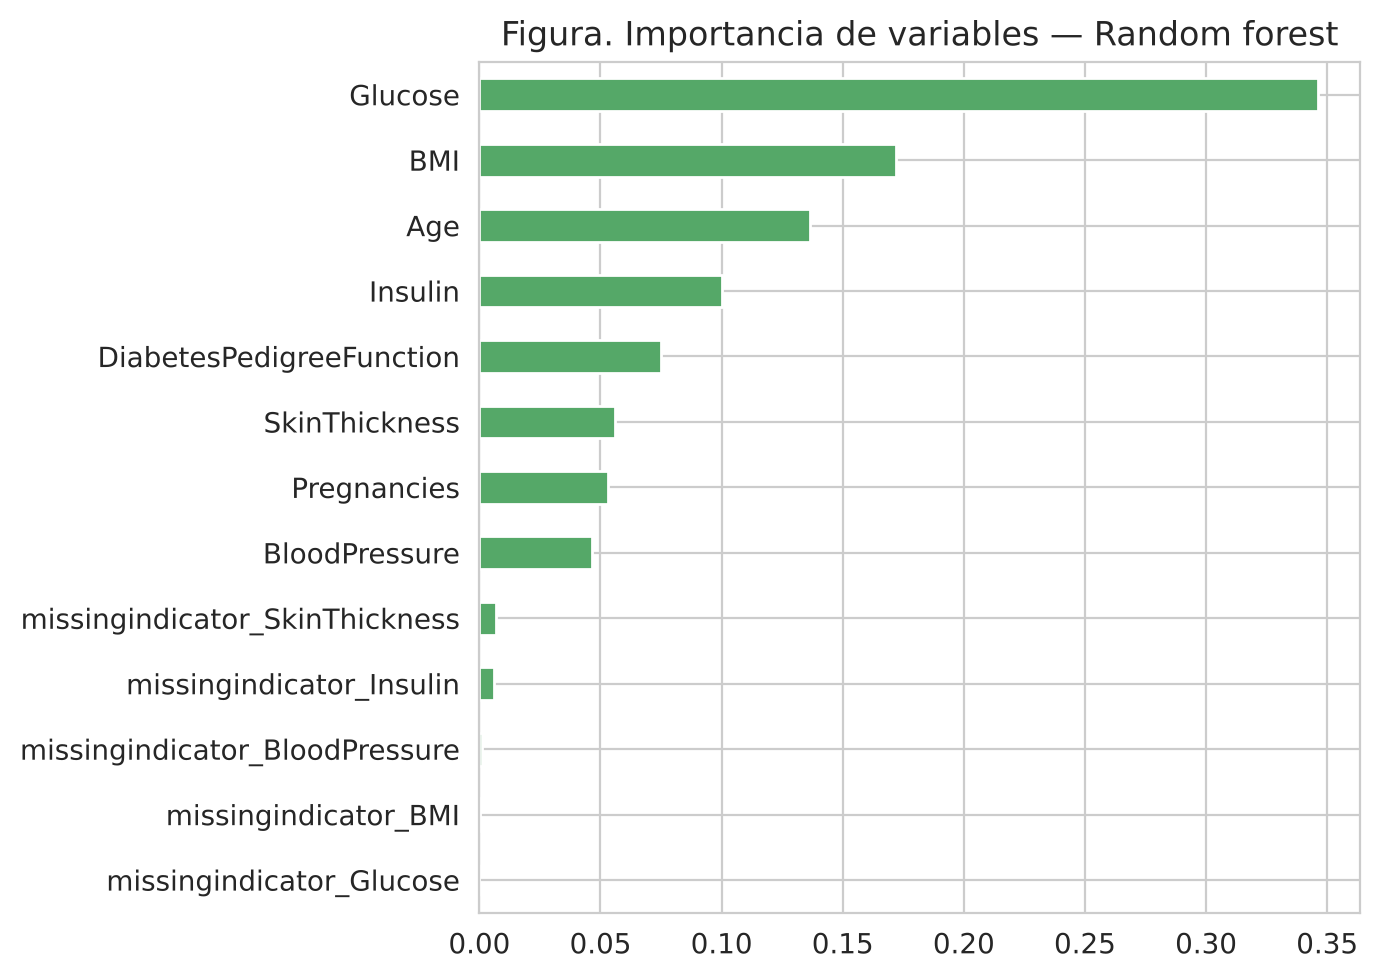

Glucose                           0.346
BMI                               0.172
Age                               0.136
Insulin                           0.100
DiabetesPedigreeFunction          0.075
SkinThickness                     0.056
Pregnancies                       0.053
BloodPressure                     0.046
missingindicator_SkinThickness    0.007
missingindicator_Insulin          0.006
missingindicator_BloodPressure    0.001
missingindicator_BMI              0.000
missingindicator_Glucose          0.000
Variables 'missingindicator_*' = indicador de que el valor original era un cero imposible (dato faltante).


In [33]:
prueba = X_test.copy(); prueba["real"] = y_test; prueba["pred"] = pred_final
prueba["Insulina_faltante"] = prueba["Insulin"].isna()
grupos = {"FN (diabética no detectada)": (prueba.real == 1) & (prueba.pred == 0),
          "VP (diabética detectada)": (prueba.real == 1) & (prueba.pred == 1),
          "FP (falsa alarma)": (prueba.real == 0) & (prueba.pred == 1),
          "VN (no diabética bien clasificada)": (prueba.real == 0) & (prueba.pred == 0)}
perfil = pd.DataFrame({
    g: {"n": int(m.sum()), "Glucose (media)": prueba.loc[m, "Glucose"].mean(), "BMI (media)": prueba.loc[m, "BMI"].mean(),
        "Age (media)": prueba.loc[m, "Age"].mean(), "% con Insulin faltante": prueba.loc[m, "Insulina_faltante"].mean() * 100}
    for g, m in grupos.items()}).round(1)
display(perfil)

nombres = modelo_final.named_steps["imputer"].get_feature_names_out(X_train.columns)
clf_final = modelo_final.named_steps["clf"]
if hasattr(clf_final, "feature_importances_"):
    imp_final = pd.Series(clf_final.feature_importances_, index=nombres).sort_values()
    titulo = "Importancia de variables"
else:
    imp_final = pd.Series(clf_final.coef_[0], index=nombres).sort_values(); titulo = "Coeficientes"
fig, ax = plt.subplots(figsize=(7, 5))
imp_final.plot(kind="barh", ax=ax, color="#55A868"); ax.set_title(f"Figura. {titulo} — {nombre_final}")
plt.tight_layout(); plt.show()
print(imp_final.sort_values(ascending=False).round(3).to_string())
print("Variables 'missingindicator_*' = indicador de que el valor original era un cero imposible (dato faltante).")

**Interpretación:** las 11 diabéticas no detectadas tienen en promedio menor glucosa (110,0 frente a 147,7 en las detectadas), menor IMC (30,7 frente a 35,9) y menor edad (28,3 frente a 38,4 años): el modelo falla más en casos con señales menos marcadas, lo que es coherente con que la glucosa sea la variable más importante. El porcentaje con `Insulin` faltante es similar (63,6 % frente a 60,5 %), así que no hay evidencia de que los datos faltantes expliquen esos errores. Las 27 falsas alarmas tienen un perfil parecido al de las diabéticas (glucosa 141,2 frente a 100,5 en las no diabéticas bien clasificadas; IMC 36,6 frente a 29,1); con estos datos no se puede saber si son errores reales del modelo o mujeres con riesgo elevado que no fueron diagnosticadas en el registro. Son pocos casos y se describen solo como asociaciones. En importancia de variables dominan `Glucose` (0,346), `BMI` (0,172), `Age` (0,136) e `Insulin` (0,100); los indicadores de faltante suman 0,014. Esas importancias describen lo que el modelo usa, no efectos causales.

In [34]:
resultados_finales = {
    "modelo_final": nombre_final, "imputacion": IMPUTADOR_ELEGIDO, "umbral": UMBRAL,
    "parametros": {k: (None if v is None else v) for k, v in busquedas[nombre_final].best_params_.items()},
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "metricas_prueba": tabla_final.reset_index().to_dict(orient="records"),
    "matriz_confusion_prueba": {"VP": int(tp), "VN": int(tn), "FP": int(fp), "FN": int(fn)},
}
with open("resultados_finales.json", "w") as f:
    json.dump(resultados_finales, f, ensure_ascii=False, indent=1, default=str)
print("Guardado resultados_finales.json")

Guardado resultados_finales.json


## 12b. Guardado del pipeline final para la aplicación (corte 3)

Se guarda el **pipeline final completo** (imputación + modelo ajustado), el orden de las columnas y el umbral. La aplicación debe cargar estos tres archivos, **no reentrenar**, convertir los ceros imposibles a `NaN` antes de predecir (igual que en el entrenamiento, función `preparar_entrada`) y clasificar con `probabilidad >= umbral`.

In [35]:
import joblib, sklearn

COLS_CERO_IMPOSIBLE = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
def preparar_entrada(df_entrada):
    """Misma transformación del entrenamiento: ceros imposibles -> NaN y orden de columnas."""
    d = df_entrada[list(X_train.columns)].copy()
    d[COLS_CERO_IMPOSIBLE] = d[COLS_CERO_IMPOSIBLE].replace(0, np.nan)
    return d

joblib.dump(modelo_final, "modelo_diabetes.joblib")
joblib.dump(list(X_train.columns), "columnas.joblib")
joblib.dump(float(UMBRAL), "umbral.joblib")

# Comprobación: cargar los archivos y predecir un registro del conjunto de prueba
modelo = joblib.load("modelo_diabetes.joblib"); umbral = joblib.load("umbral.joblib")
registro = X_test.iloc[[0]]
p1 = modelo.predict_proba(registro)[0, 1]
print("Índice del registro:", registro.index[0])
print("Probabilidad de diabetes:", round(p1, 4), "| Clase (umbral %.2f):" % umbral, int(p1 >= umbral))
print("scikit-learn:", sklearn.__version__)
assert np.allclose(modelo.predict_proba(X_test)[:, 1], prob_test), "El modelo cargado no coincide con el evaluado"
print("OK: el pipeline guardado reproduce exactamente las probabilidades evaluadas en prueba.")

Índice del registro: 44
Probabilidad de diabetes: 0.6716 | Clase (umbral 0.50): 1
scikit-learn: 1.6.1
OK: el pipeline guardado reproduce exactamente las probabilidades evaluadas en prueba.


### Registros de referencia para la prueba de consistencia (notebook vs. Streamlit)

Estos registros se escriben **como los ingresaría un usuario** (con 0 en los campos desconocidos). Al ingresar los mismos valores en la aplicación, la probabilidad y la clase deben coincidir con la tabla.

In [36]:
referencia = pd.DataFrame([
    {"Caso": "Representativo (registro 44 de prueba)", **{c: (0 if pd.isna(v) else v) for c, v in X_test.iloc[0].items()}},
    {"Caso": "Valores límite altos", "Pregnancies": 17, "Glucose": 199, "BloodPressure": 122, "SkinThickness": 99, "Insulin": 846, "BMI": 67.1, "DiabetesPedigreeFunction": 2.42, "Age": 81},
    {"Caso": "Valores límite bajos", "Pregnancies": 0, "Glucose": 44, "BloodPressure": 24, "SkinThickness": 7, "Insulin": 14, "BMI": 18.2, "DiabetesPedigreeFunction": 0.078, "Age": 21},
    {"Caso": "Con campos desconocidos (ceros)", "Pregnancies": 2, "Glucose": 120, "BloodPressure": 0, "SkinThickness": 0, "Insulin": 0, "BMI": 30.5, "DiabetesPedigreeFunction": 0.35, "Age": 33},
]).set_index("Caso")
entrada = preparar_entrada(referencia)
referencia["Probabilidad"] = modelo.predict_proba(entrada)[:, 1].round(4)
referencia["Clase (umbral)"] = (referencia["Probabilidad"] >= umbral).astype(int)
referencia

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Probabilidad,Clase (umbral)
Caso,,,,,,,,,,
Representativo (registro 44 de prueba),7.0,159.0,64.0,0,0,27.4,0.294,40.0,0.6716,1
Valores límite altos,17.0,199.0,122.0,99,846,67.1,2.420,81.0,0.8278,1
Valores límite bajos,0.0,44.0,24.0,7,14,18.2,0.078,21.0,0.0549,0
Con campos desconocidos (ceros),2.0,120.0,0.0,0,0,30.5,0.350,33.0,0.5661,1


## 13. Conclusiones finales

**Principales hallazgos del EDA**
- El 34,9 % de las pacientes (268 de 768) es diabética: desbalance moderado, por lo que el accuracy por sí solo es insuficiente.
- `Glucose` es la variable más asociada al diagnóstico (r = 0,49), seguida de `BMI` (0,31), `Age` (0,24) y `Pregnancies` (0,22). La tasa de diabetes crece con el IMC y es menor en mujeres de 21-30 años.
- `Insulin` (48,7 %) y `SkinThickness` (29,6 %) tienen muchos ceros imposibles; los porcentajes son similares en ambas clases. No se eliminaron registros atípicos.

**Modelado y desempeño**
- El modelo final es un **random forest ajustado** (imputación por mediana con indicador de faltante, umbral 0,5). En las 154 pacientes de prueba obtuvo accuracy 0,753, precision 0,614, recall 0,796, F1 0,694 y AUC-ROC 0,823, con 11 diabéticas no detectadas y 27 falsas alarmas.
- Mejora de forma modesta al modelo base del corte 2 (regresión logística: F1 0,650; recall 0,704; 16 no detectadas), sobre todo en recall. Las diferencias entre modelos en validación cruzada anidada son menores que su variabilidad, por lo que la preferencia por el random forest es moderada.
- El F1 queda ligeramente por debajo de 0,70; se documentó la revisión (línea base, imputación, hiperparámetros y umbral) sin alterar la partición ni la métrica.

**Pruebas de la aplicación**
- La sección 12b entrega registros de referencia con su probabilidad y clase para comprobar que la aplicación produce el mismo resultado que este notebook. Los resultados de esas pruebas se reportan en el artículo.

**Limitaciones**
- Evaluación sobre solo 154 pacientes (54 diabéticas); un caso cambia el recall en cerca de 0,019.
- No hay validación externa: el dataset solo incluye mujeres de origen Pima de 21 años o más, lo que limita la generalización.
- La glucosa a 2 h es parte del criterio diagnóstico, por lo que el problema se parece más a apoyo al diagnóstico que a predicción temprana.
- El umbral 0,5 se mantuvo por una regla estadística, no por un costo clínico explícito de cada error.
- Los resultados muestran asociaciones, no causalidad. Esta herramienta es **académica** y no sustituye una valoración profesional de salud.

**Trabajo futuro**
- Validar con otra población o conjunto de datos y calibrar las probabilidades.
- Definir el umbral con costos explícitos de falsos negativos y falsos positivos junto con criterio clínico.
- Probar otros modelos (por ejemplo, gradient boosting) y repetir la validación cruzada con varias semillas.

## 14. Declaración y evaluación del uso de inteligencia artificial (entrega final)

Los campos marcados con **[completar]** deben ser llenados por el grupo: solo el grupo puede afirmar qué verificó y comprendió.

| Elemento | Información |
|---|---|
| **Herramienta y propósito** | Claude (Anthropic), en chat: análisis de la guía de la entrega final, revisión del notebook del corte 3 y propuesta de las secciones 12.4 a 12.9 y 12b (línea base, comparación de imputaciones, ajuste de hiperparámetros, umbral, evaluación final, análisis de errores, guardado del pipeline y registros de referencia). |
| **Prompt** | Mensajes enviados: «analiza este documento» (guía de la entrega final); «según tú qué es lo que llevo ahora»; «recuerda que hicimos el avance de corte 3 que subí a github todo lo que me dijiste más el streamlit»; envío del notebook `Avance3_Proyecto_Mineria_Datos.ipynb`; «corrige lo que falta y dime qué más falta». **[completar: pegar aquí los prompts completos si se usaron otros]** |
| **Respuesta recibida** | Diagnóstico del notebook (era el del corte 2 más el guardado del pipeline; F1 de 0,650 por debajo de 0,70; faltaban ajuste, umbral, análisis de errores del modelo final y declaración de IA) y notebook corregido con las secciones nuevas ejecutadas. |
| **Verificación** | Realizada al generar el notebook: se reejecutó completo sin errores; las métricas del corte 2 se reprodujeron exactamente (regresión logística: accuracy 0,734, F1 0,650, AUC 0,813); el pipeline guardado reproduce las probabilidades de prueba (`assert` en 12b). La primera ejecución de las celdas nuevas se hizo con una copia pública del dataset Pima. **[completar: reejecutar en Colab con su propio `diabetes.csv` y confirmar que las cifras de este notebook coinciden]** |
| **Evaluación crítica** | **[completar: qué fue correcto, parcial o incorrecto]** Puntos a evaluar: si las columnas usadas son las reales del dataset, si el código se ejecutó, si las métricas del texto coinciden con las salidas, y si la interpretación (por ejemplo, que el F1 de 0,694 es una mejora modesta y no distinguible de 0,70) es honesta frente a los datos. |
| **Problemas identificados** | La herramienta no pudo abrir el enlace de Colab ni el repositorio, y al inicio dio por pendiente el corte 3 que el estudiante ya había entregado; se corrigió con la información del estudiante. **[completar: otros errores, omisiones o contenido no solicitado]** |
| **Ajustes y decisión final** | **[completar: qué se conservó, qué se corrigió y por qué; incluir si se acepta el cambio de modelo final a random forest]** |

La declaración de responsabilidad requerida por la guía se incluye en el artículo.